In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

REPORT_DIR = PROJECT_ROOT / "reports" / "stage_3"
TABLE_DIR = REPORT_DIR / "tables"
FIGURE_DIR = REPORT_DIR / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = DATA_RAW / "train.csv"
EVENTS_FILE = DATA_RAW / "holidays_events.csv"
SERIES_FILE = DATA_PROCESSED / "store1_grocery1_daily_prepared.csv"

print("Project root:", PROJECT_ROOT)
print("Train file exists:", TRAIN_FILE.exists())
print("Events file exists:", EVENTS_FILE.exists())
print("Prepared series exists:", SERIES_FILE.exists())

Project root: /home/wicky/projects/demand-forecasting-replenishment-engine
Train file exists: True
Events file exists: True
Prepared series exists: True


In [3]:
#Load
if not TRAIN_FILE.exists():
    raise FileNotFoundError(TRAIN_FILE)

if not EVENTS_FILE.exists():
    raise FileNotFoundError(EVENTS_FILE)

if not SERIES_FILE.exists():
    raise FileNotFoundError(SERIES_FILE)

train = pd.read_csv(TRAIN_FILE)

events = pd.read_csv(EVENTS_FILE)

series = pd.read_csv(SERIES_FILE)

series["date"] = pd.to_datetime(series["date"])

events["date"] = pd.to_datetime(events["date"])

train["date"] = pd.to_datetime(train["date"])

print("Train shape:", train.shape)
print("Events shape:", events.shape)
print("Prepared series shape:", series.shape)

display(train.head())
display(events.head())
display(series.head())

Train shape: (3000888, 6)
Events shape: (350, 6)
Prepared series shape: (1688, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


,date,sales,day_of_week,month,year,is_missing_sales
0,2013-01-01,0.0,1,1,2013,False
1,2013-01-02,2652.0,2,1,2013,False
2,2013-01-03,2121.0,3,1,2013,False
3,2013-01-04,2056.0,4,1,2013,False
4,2013-01-05,2216.0,5,1,2013,False


In [4]:
#inspect
print("TRAIN COLUMNS")
print(train.columns.tolist())

print("\nEVENT COLUMNS")
print(events.columns.tolist())

print("\nTRAIN DATA TYPES")
display(train.dtypes.to_frame("dtype"))

print("\nEVENT DATA TYPES")
display(events.dtypes.to_frame("dtype"))

print("\nTRAIN SAMPLE")
display(train.head(10))

print("\nEVENT SAMPLE")
display(events.head(10))

TRAIN COLUMNS
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

EVENT COLUMNS
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

TRAIN DATA TYPES


,dtype
id,int64
date,datetime64[us]
store_nbr,int64
family,str
sales,float64
onpromotion,int64



EVENT DATA TYPES


,dtype
date,datetime64[us]
type,str
locale,str
locale_name,str
description,str
transferred,bool



TRAIN SAMPLE


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0
5,5,2013-01-01,1,BREAD/BAKERY,0.0,0
6,6,2013-01-01,1,CELEBRATION,0.0,0
7,7,2013-01-01,1,CLEANING,0.0,0
8,8,2013-01-01,1,DAIRY,0.0,0
9,9,2013-01-01,1,DELI,0.0,0



EVENT SAMPLE


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
6,2012-06-23,Holiday,Local,Guaranda,Cantonizacion de Guaranda,False
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False


In [19]:
promotion_data = train[
    (train["store_nbr"] == 1)
    & (train["family"] == "GROCERY I")
].copy()

promotion_data["onpromotion"] = pd.to_numeric(
    promotion_data["onpromotion"],
    errors="coerce"
)

promotion_data["date"] = pd.to_datetime(
    promotion_data["date"]
)

promotion_data = promotion_data.sort_values("date")

total_observations = len(promotion_data)

promotion_days = (
    promotion_data["onpromotion"] > 0
).sum()

total_promoted_items = (
    promotion_data["onpromotion"].sum()
)

mean_promotion_count = (
    promotion_data["onpromotion"].mean()
)

promotion_day_percentage = (
    promotion_days / total_observations * 100
)

print("Promotion audit — Store 1, GROCERY I")
print("-" * 50)

print("Daily observations:", total_observations)

print("Days with promotions:", promotion_days)

print(
    "Days without promotions:",
    total_observations - promotion_days
)

print(
    "Percentage of days with promotions:",
    round(promotion_day_percentage, 2), "%"
)

print(
    "Total promotion count across daily records:",
    total_promoted_items
)

print(
    "Mean promotion count per day:",
    round(mean_promotion_count, 2)
)

print(
    "Maximum promotion count in one observation:",
    promotion_data["onpromotion"].max()
)

print(
    "Missing promotion records:",
    promotion_data["onpromotion"].isna().sum()
)

promotion_data.to_csv(
    TABLE_DIR / "target_series_promotion_audit.csv",
    index=False
)

Promotion audit — Store 1, GROCERY I
--------------------------------------------------
Daily observations: 1684
Days with promotions: 1110
Days without promotions: 574
Percentage of days with promotions: 65.91 %
Total promotion count across daily records: 29572
Mean promotion count per day: 17.56
Maximum promotion count in one observation: 167
Missing promotion records: 0


In [20]:
promotion_data["promotion_intensity"] = pd.cut(
    promotion_data["onpromotion"],
    bins=[-1, 0, 5, 10, 20, 50, np.inf],
    labels=[
        "None",
        "1-5",
        "6-10",
        "11-20",
        "21-50",
        "Above 50"
    ]
)

promotion_intensity_analysis = (
    promotion_data
    .groupby("promotion_intensity", observed=True)
    .agg(
        observations=("sales", "count"),
        mean_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        std_sales=("sales", "std"),
        total_sales=("sales", "sum")
    )
    .reset_index()
)

display(promotion_intensity_analysis)

promotion_intensity_analysis.to_csv(
    TABLE_DIR / "promotion_intensity_sales_analysis.csv",
    index=False
)


,promotion_intensity,observations,mean_sales,median_sales,std_sales,total_sales
0,None,574,1873.156794,1965.0,619.951625,1075192.0
1,1-5,258,2094.468992,2190.0,644.591042,540373.0
2,6-10,195,2312.712821,2377.0,683.529432,450979.0
3,11-20,151,2355.807947,2431.0,1013.355533,355727.0
4,21-50,308,2465.012987,2561.0,744.162634,759224.0
5,Above 50,198,2840.040404,2837.0,741.094915,562328.0


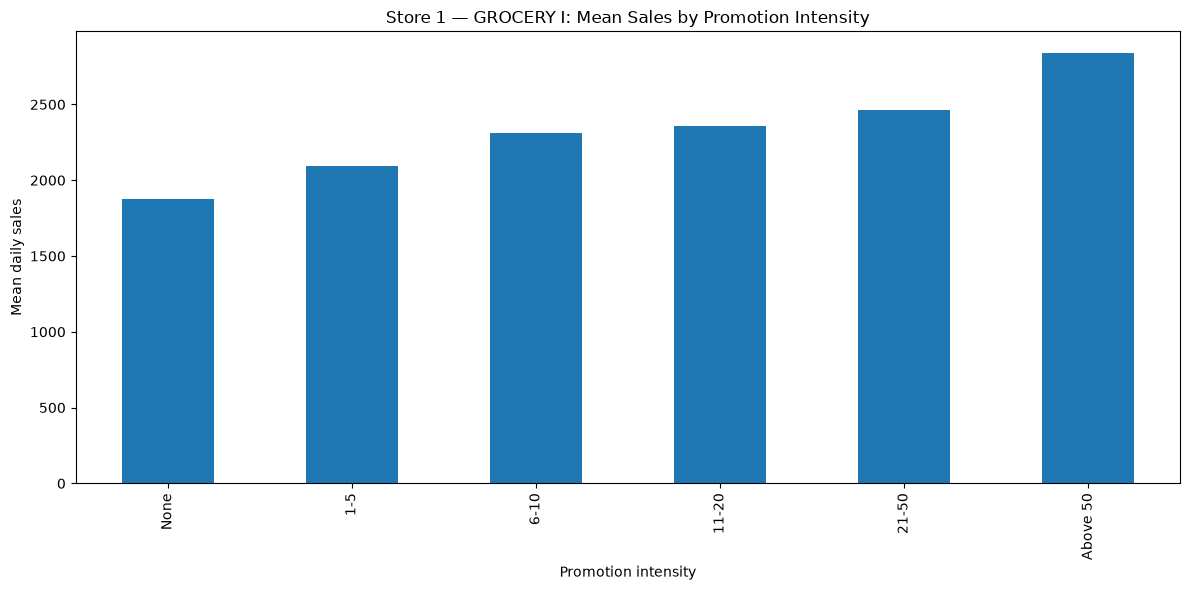

In [21]:
plt.figure(figsize=(12, 6))

promotion_intensity_analysis.set_index(
    "promotion_intensity"
)["mean_sales"].plot(kind="bar")

plt.title(
    "Store 1 — GROCERY I: "
    "Mean Sales by Promotion Intensity"
)

plt.xlabel("Promotion intensity")
plt.ylabel("Mean daily sales")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "promotion_intensity_sales.png",
    dpi=150
)

plt.show()


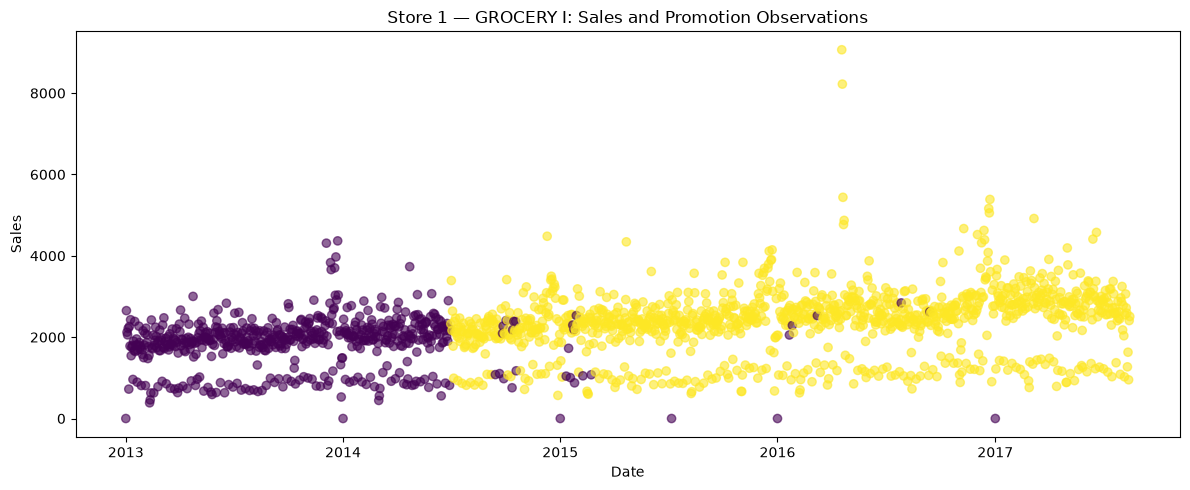

In [8]:
#plot promotion
if "onpromotion" in promotion_data.columns:

    promotion_data["promotion_flag"] = (
        promotion_data["onpromotion"] > 0
    )

    plt.figure(figsize=(12, 5))

    plt.scatter(
        promotion_data["date"],
        promotion_data["sales"],
        c=promotion_data["promotion_flag"],
        alpha=0.6
    )

    plt.title(
        "Store 1 — GROCERY I: Sales and Promotion Observations"
    )

    plt.xlabel("Date")
    plt.ylabel("Sales")

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "promotion_sales_scatter.png",
        dpi=150
    )

    plt.show()

In [9]:
#holiday and event audit
display(events.head())

print("Number of event records:", len(events))

print("Event columns:", events.columns.tolist())

if "type" in events.columns:

    event_type_counts = (
        events["type"]
        .value_counts(dropna=False)
        .rename("count")
        .reset_index()
    )

    display(event_type_counts)

    event_type_counts.to_csv(
        TABLE_DIR / "event_type_distribution.csv",
        index=False
    )

if "locale" in events.columns:

    locale_counts = (
        events["locale"]
        .value_counts(dropna=False)
        .rename("count")
        .reset_index()
    )

    display(locale_counts)

    locale_counts.to_csv(
        TABLE_DIR / "event_locale_distribution.csv",
        index=False
    )

if "locale_name" in events.columns:

    display(
        events["locale_name"]
        .value_counts(dropna=False)
        .head(30)
        .to_frame("count")
    )

if "transferred" in events.columns:

    display(
        events["transferred"]
        .value_counts(dropna=False)
        .to_frame("count")
    )

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


Number of event records: 350
Event columns: ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']


,type,count
0,Holiday,221
1,Event,56
2,Additional,51
3,Transfer,12
4,Bridge,5
5,Work Day,5


,locale,count
0,National,174
1,Local,152
2,Regional,24


,count
locale_name,
Ecuador,174
Quito,13
Riobamba,12
Guaranda,12
Latacunga,12
Ambato,12
Guayaquil,11
Cuenca,7
Ibarra,7


,count
transferred,
False,338
True,12


In [10]:
#Events on target series
event_dates = events.copy()

event_dates["date"] = pd.to_datetime(
    event_dates["date"]
)

event_dates = event_dates.sort_values("date")

target_calendar = series[
    ["date", "sales"]
].copy()

event_join = target_calendar.merge(
    event_dates,
    on="date",
    how="left"
)

display(event_join.head(20))

event_join.to_csv(
    TABLE_DIR / "target_series_event_alignment.csv",
    index=False
)

print("Target series rows:", len(target_calendar))

print(
    "Target series dates with event records:",
    event_join["type"].notna().sum()
    if "type" in event_join.columns
    else "Event type unavailable"
)

,date,sales,type,locale,locale_name,description,transferred
0,2013-01-01,0.0,Holiday,National,Ecuador,Primer dia del ano,False
1,2013-01-02,2652.0,NaN,NaN,NaN,NaN,NaN
2,2013-01-03,2121.0,NaN,NaN,NaN,NaN,NaN
3,2013-01-04,2056.0,NaN,NaN,NaN,NaN,NaN
4,2013-01-05,2216.0,Work Day,National,Ecuador,Recupero puente Navidad,False
5,2013-01-06,723.0,NaN,NaN,NaN,NaN,NaN
6,2013-01-07,2262.0,NaN,NaN,NaN,NaN,NaN
7,2013-01-08,1782.0,NaN,NaN,NaN,NaN,NaN
8,2013-01-09,2429.0,NaN,NaN,NaN,NaN,NaN
9,2013-01-10,1544.0,NaN,NaN,NaN,NaN,NaN


Target series rows: 1688
Target series dates with event records: 286


In [11]:
#event coverage and category assessment
if "type" in event_join.columns:

    event_coverage = (
        event_join
        .groupby("type", dropna=False)
        .agg(
            dates=("date", "count"),
            average_sales=("sales", "mean"),
            median_sales=("sales", "median")
        )
        .reset_index()
    )

    display(event_coverage)

    event_coverage.to_csv(
        TABLE_DIR / "event_sales_descriptive_analysis.csv",
        index=False
    )

,type,dates,average_sales,median_sales
0,Additional,38,2801.868421,2670.5
1,Bridge,3,1851.333333,1686.0
2,Event,56,2597.714286,2531.5
3,Holiday,175,1926.847953,2097.0
4,Transfer,9,1372.000000,1218.0
5,Work Day,5,2488.200000,2475.0
6,NaN,1432,2235.925279,2295.0


In [12]:
#Calendar feature audit
calendar_data = series.copy()

calendar_data["date"] = pd.to_datetime(
    calendar_data["date"]
)

calendar_data["day_of_week"] = (
    calendar_data["date"].dt.dayofweek
)

calendar_data["month"] = (
    calendar_data["date"].dt.month
)

calendar_data["year"] = (
    calendar_data["date"].dt.year
)

calendar_data["day_of_month"] = (
    calendar_data["date"].dt.day
)

calendar_data["week_of_year"] = (
    calendar_data["date"].dt.isocalendar().week.astype(int)
)

calendar_data["quarter"] = (
    calendar_data["date"].dt.quarter
)

calendar_data["is_weekend"] = (
    calendar_data["day_of_week"] >= 5
)

display(calendar_data.head())

calendar_data.to_csv(
    TABLE_DIR / "calendar_feature_audit.csv",
    index=False
)

/tmp/ipykernel_37160/1249228762.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  calendar_data["date"].dt.dayofweek


,date,sales,day_of_week,month,year,is_missing_sales,day_of_month,week_of_year,quarter,is_weekend
0,2013-01-01,0.0,1,1,2013,False,1,1,1,False
1,2013-01-02,2652.0,2,1,2013,False,2,1,1,False
2,2013-01-03,2121.0,3,1,2013,False,3,1,1,False
3,2013-01-04,2056.0,4,1,2013,False,4,1,1,False
4,2013-01-05,2216.0,5,1,2013,False,5,1,1,True


In [13]:
#weekely and monthly patterns
weekday_analysis = (
    calendar_data
    .groupby("day_of_week")["sales"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
)

weekday_analysis.index = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

display(weekday_analysis)

weekday_analysis.to_csv(
    TABLE_DIR / "weekday_sales_analysis.csv"
)

monthly_analysis = (
    calendar_data
    .groupby("month")["sales"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
)

display(monthly_analysis)

monthly_analysis.to_csv(
    TABLE_DIR / "monthly_sales_analysis.csv"
)

,count,mean,median,std
Monday,241,2383.493776,2336.0,704.867955
Tuesday,242,2408.991736,2384.0,732.843040
Wednesday,240,2770.362500,2687.0,596.370457
Thursday,240,2229.045833,2149.5,521.601992
Friday,240,2413.645833,2356.5,699.768464
Saturday,241,2322.962656,2289.0,451.130657
Sunday,240,1031.075000,1006.5,281.185540


,count,mean,median,std
month,,,,
1,155,2109.903226,2208.0,746.221171
2,141,2091.872340,2193.0,748.043418
3,155,2214.729032,2289.0,743.179387
4,150,2343.973333,2308.0,1086.937308
5,155,2183.412903,2295.0,721.858332
6,150,2268.526667,2326.5,713.742116
7,155,2178.774194,2275.0,648.262238
8,139,2033.323741,2155.0,640.865902
9,120,2126.658333,2251.5,535.530107


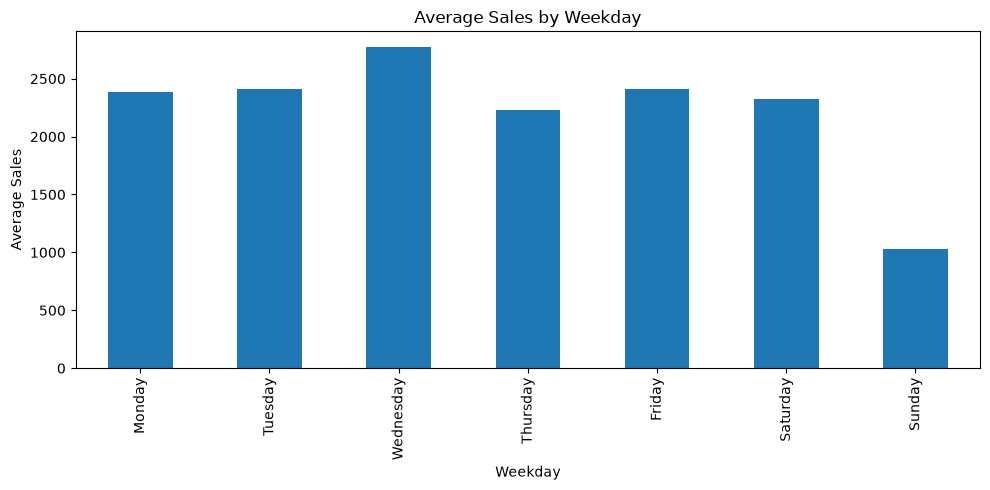

In [14]:
#calendar pattern visualization
plt.figure(figsize=(10, 5))

weekday_analysis["mean"].plot(kind="bar")

plt.title("Average Sales by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Sales")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "weekday_sales.png",
    dpi=150
)

plt.show()

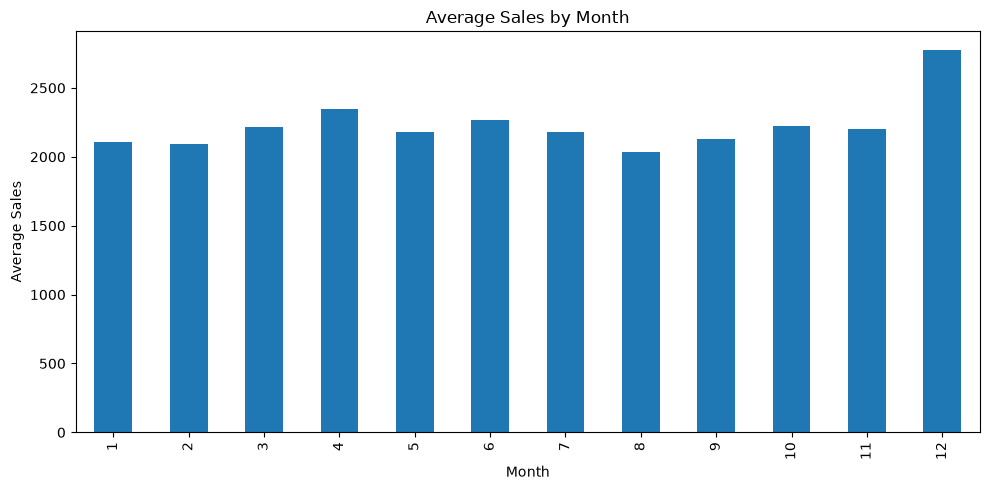

In [15]:
plt.figure(figsize=(10, 5))

monthly_analysis["mean"].plot(kind="bar")

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "monthly_sales.png",
    dpi=150
)

plt.show()

In [16]:
#missingness
audit_columns = [
    "date",
    "sales",
    "day_of_week",
    "month",
    "year",
    "is_missing_sales"
]

audit_columns = [
    column
    for column in audit_columns
    if column in series.columns
]

missingness_report = (
    series[audit_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)

missingness_report["missing_percentage"] = (
    missingness_report["missing_count"]
    / len(series)
    * 100
)

display(missingness_report)

missingness_report.to_csv(
    TABLE_DIR / "prepared_series_missingness.csv"
)

,missing_count,missing_percentage
date,0,0.000000
sales,4,0.236967
day_of_week,0,0.000000
month,0,0.000000
year,0,0.000000
is_missing_sales,0,0.000000


In [17]:
#forecast availability
forecast_issue_date = series["date"].max()

forecast_horizon = 30

forecast_dates = pd.date_range(
    start=forecast_issue_date + pd.Timedelta(days=1),
    periods=forecast_horizon,
    freq="D"
)

future_calendar = pd.DataFrame(
    {"date": forecast_dates}
)

future_calendar["day_of_week"] = (
    future_calendar["date"].dt.dayofweek
)

future_calendar["month"] = (
    future_calendar["date"].dt.month
)

future_calendar["year"] = (
    future_calendar["date"].dt.year
)

future_calendar["week_of_year"] = (
    future_calendar["date"].dt.isocalendar().week.astype(int)
)

future_calendar["quarter"] = (
    future_calendar["date"].dt.quarter
)

future_calendar["is_weekend"] = (
    future_calendar["day_of_week"] >= 5
)

display(future_calendar)

future_calendar.to_csv(
    TABLE_DIR / "future_calendar_features.csv",
    index=False
)

/tmp/ipykernel_37160/2437181872.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  future_calendar["date"].dt.dayofweek


,date,day_of_week,month,year,week_of_year,quarter,is_weekend
0,2017-08-16,2,8,2017,33,3,False
1,2017-08-17,3,8,2017,33,3,False
2,2017-08-18,4,8,2017,33,3,False
3,2017-08-19,5,8,2017,33,3,True
4,2017-08-20,6,8,2017,33,3,True
5,2017-08-21,0,8,2017,34,3,False
6,2017-08-22,1,8,2017,34,3,False
7,2017-08-23,2,8,2017,34,3,False
8,2017-08-24,3,8,2017,34,3,False
9,2017-08-25,4,8,2017,34,3,False


In [27]:
# ============================================================
# STAGE 3 — STORE 1 EVENT APPLICABILITY & FEATURE AUDIT
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. VERIFIED STORE LOCATION
# ------------------------------------------------------------

STORE_CITY = "Quito"
STORE_PROVINCE = "Pichincha"
STORE_COUNTRY = "Ecuador"

store1_metadata = stores_metadata.loc[
    stores_metadata["store_nbr"] == 1
].copy()

if store1_metadata.empty:
    raise ValueError("Store 1 metadata was not found.")

print("Verified store metadata:")
display(store1_metadata)

# ------------------------------------------------------------
# 2. NORMALIZE EVENT DATA
# ------------------------------------------------------------

events_audit = events.copy()

events_audit["date"] = pd.to_datetime(
    events_audit["date"]
)

events_audit["locale"] = (
    events_audit["locale"]
    .astype(str)
    .str.strip()
)

events_audit["locale_name"] = (
    events_audit["locale_name"]
    .astype(str)
    .str.strip()
)

events_audit["type"] = (
    events_audit["type"]
    .astype(str)
    .str.strip()
)

events_audit["transferred"] = (
    events_audit["transferred"]
    .astype(bool)
)

# ------------------------------------------------------------
# 3. PRELIMINARY GEOGRAPHIC APPLICABILITY
# ------------------------------------------------------------

national_events = events_audit[
    events_audit["locale_name"] == STORE_COUNTRY
].copy()

regional_events = events_audit[
    (
        events_audit["locale"] == "Regional"
    )
    &
    (
        events_audit["locale_name"] == STORE_PROVINCE
    )
].copy()

local_events = events_audit[
    (
        events_audit["locale"] == "Local"
    )
    &
    (
        events_audit["locale_name"] == STORE_CITY
    )
].copy()

applicable_events = pd.concat(
    [
        national_events,
        regional_events,
        local_events
    ],
    ignore_index=True
)

applicable_events = (
    applicable_events
    .drop_duplicates()
    .sort_values("date")
    .reset_index(drop=True)
)

print("All source event records:", len(events_audit))
print("National records:", len(national_events))
print("Regional records:", len(regional_events))
print("Local records:", len(local_events))
print(
    "Potentially applicable records:",
    len(applicable_events)
)

display(applicable_events.head(30))

# ------------------------------------------------------------
# 4. SAVE APPLICABLE RAW EVENT RECORDS
# ------------------------------------------------------------

applicable_events.to_csv(
    TABLE_DIR / "potentially_applicable_store1_events.csv",
    index=False
)

# ------------------------------------------------------------
# 5. TRANSFER AUDIT
# ------------------------------------------------------------

transfer_records = events_audit[
    (
        events_audit["transferred"] == True
    )
    |
    (
        events_audit["type"] == "Transfer"
    )
].copy()

transfer_records = transfer_records.sort_values(
    "date"
)

print("\nTransfer-related source records:")
display(transfer_records)

transfer_records.to_csv(
    TABLE_DIR / "all_transfer_related_event_records.csv",
    index=False
)

applicable_transfer_records = applicable_events[
    (
        applicable_events["transferred"] == True
    )
    |
    (
        applicable_events["type"] == "Transfer"
    )
].copy()

print("\nPotentially applicable transfer records:")
display(applicable_transfer_records)

applicable_transfer_records.to_csv(
    TABLE_DIR / "applicable_transfer_records.csv",
    index=False
)

# ------------------------------------------------------------
# 6. EVENT DATE FEATURE ENGINEERING
# ------------------------------------------------------------

event_types = [
    "Holiday",
    "Event",
    "Additional",
    "Transfer",
    "Bridge",
    "Work Day"
]

event_features = applicable_events.copy()

for event_type in event_types:

    feature_name = (
        "event_type_"
        + event_type.lower().replace(" ", "_")
    )

    event_features[feature_name] = (
        event_features["type"] == event_type
    ).astype(int)

event_features["is_transferred_record"] = (
    event_features["transferred"].astype(int)
)

# Aggregate multiple records per date.
aggregation_rules = {
    "type": "count",
    "transferred": "sum"
}

for event_type in event_types:

    feature_name = (
        "event_type_"
        + event_type.lower().replace(" ", "_")
    )

    aggregation_rules[feature_name] = "sum"

event_features_daily = (
    event_features
    .groupby("date")
    .agg(aggregation_rules)
    .reset_index()
)

event_features_daily = (
    event_features_daily
    .rename(
        columns={
            "type": "event_record_count",
            "transferred": "transferred_record_count"
        }
    )
)

print("\nDaily event features:")
display(event_features_daily.head(30))

event_features_daily.to_csv(
    TABLE_DIR / "preliminary_event_date_features.csv",
    index=False
)

# ------------------------------------------------------------
# 7. ALIGN EVENT FEATURES TO THE TARGET SERIES
# ------------------------------------------------------------

target_calendar = series[
    ["date", "sales"]
].copy()

target_calendar["date"] = pd.to_datetime(
    target_calendar["date"]
)

target_event_calendar = target_calendar.merge(
    event_features_daily,
    on="date",
    how="left"
)

event_feature_columns = [
    column
    for column in event_features_daily.columns
    if column != "date"
]

target_event_calendar[event_feature_columns] = (
    target_event_calendar[event_feature_columns]
    .fillna(0)
)

display(target_event_calendar.head(30))

target_event_calendar.to_csv(
    TABLE_DIR / "target_series_event_feature_calendar.csv",
    index=False
)

# ------------------------------------------------------------
# 8. EVENT COVERAGE
# ------------------------------------------------------------

event_coverage = pd.DataFrame(
    {
        "feature": event_feature_columns,
        "total": [
            target_event_calendar[column].sum()
            for column in event_feature_columns
        ],
        "dates_with_feature": [
            (
                target_event_calendar[column] > 0
            ).sum()
            for column in event_feature_columns
        ]
    }
)

display(event_coverage)

event_coverage.to_csv(
    TABLE_DIR / "target_event_feature_coverage.csv",
    index=False
)

# ------------------------------------------------------------
# 9. SALES DESCRIPTIVE ANALYSIS BY EVENT FLAG
# ------------------------------------------------------------

event_sales_results = []

for column in event_feature_columns:

    mask = (
        target_event_calendar[column] > 0
    )

    sales_with_event = (
        target_event_calendar.loc[mask, "sales"]
    )

    sales_without_event = (
        target_event_calendar.loc[~mask, "sales"]
    )

    event_sales_results.append(
        {
            "feature": column,
            "days_with_feature": len(sales_with_event),
            "mean_sales_with_feature": (
                sales_with_event.mean()
            ),
            "median_sales_with_feature": (
                sales_with_event.median()
            ),
            "days_without_feature": len(sales_without_event),
            "mean_sales_without_feature": (
                sales_without_event.mean()
            ),
            "median_sales_without_feature": (
                sales_without_event.median()
            )
        }
    )

event_sales_comparison = pd.DataFrame(
    event_sales_results
)

display(event_sales_comparison)

event_sales_comparison.to_csv(
    TABLE_DIR / "event_sales_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 10. MULTIPLE EVENT DATES
# ------------------------------------------------------------

multiple_event_dates = (
    applicable_events
    .groupby("date")
    .size()
    .rename("event_record_count")
    .reset_index()
)

multiple_event_dates = multiple_event_dates[
    multiple_event_dates["event_record_count"] > 1
]

display(multiple_event_dates)

multiple_event_dates.to_csv(
    TABLE_DIR / "multiple_applicable_event_dates.csv",
    index=False
)

# ------------------------------------------------------------
# 11. REPORT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STORE 1 EVENT AUDIT SUMMARY")
print("=" * 60)

print("Store:", STORE_CITY)
print("Province:", STORE_PROVINCE)
print("Country:", STORE_COUNTRY)

print(
    "Applicable source event records:",
    len(applicable_events)
)

print(
    "Applicable event dates:",
    applicable_events["date"].nunique()
)

print(
    "Dates with multiple applicable records:",
    len(multiple_event_dates)
)

print(
    "Applicable transfer-related records:",
    len(applicable_transfer_records)
)

print("\nFeature coverage:")
display(event_coverage)

print("\nSales comparison:")
display(event_sales_comparison)

print("\nAudit completed.")

Verified store metadata:


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13


All source event records: 350
National records: 174
Regional records: 0
Local records: 13
Potentially applicable records: 187


,date,type,locale,locale_name,description,transferred
0,2012-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,False
1,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
2,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
3,2012-11-02,Holiday,National,Ecuador,Dia de Difuntos,False
4,2012-11-03,Holiday,National,Ecuador,Independencia de Cuenca,False
5,2012-12-05,Additional,Local,Quito,Fundacion de Quito-1,False
6,2012-12-06,Holiday,Local,Quito,Fundacion de Quito,False
7,2012-12-21,Additional,National,Ecuador,Navidad-4,False
8,2012-12-22,Additional,National,Ecuador,Navidad-3,False
9,2012-12-23,Additional,National,Ecuador,Navidad-2,False



Transfer-related source records:


,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
20,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
73,2013-10-11,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
136,2014-10-10,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
256,2016-05-27,Transfer,National,Ecuador,Traslado Batalla de Pichincha,False
265,2016-07-24,Transfer,Local,Guayaquil,Traslado Fundacion de Guayaquil,False
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True


... (9 outputs left out)

,feature,total,dates_with_feature
0,event_record_count,159.0,155
1,transferred_record_count,7.0,7
2,event_type_holiday,55.0,55
3,event_type_event,56.0,55
4,event_type_additional,33.0,33
5,event_type_transfer,7.0,7
6,event_type_bridge,3.0,3
7,event_type_work_day,5.0,5



Sales comparison:


,feature,days_with_feature,mean_sales_with_feature,median_sales_with_feature,days_without_feature,mean_sales_without_feature,median_sales_without_feature
0,event_record_count,155,2086.112583,2052.0,1533,2236.673190,2294.0
1,transferred_record_count,7,2156.285714,2293.0,1681,2223.451998,2282.0
2,event_type_holiday,55,1071.431373,888.0,1633,2259.142682,2300.0
3,event_type_event,55,2629.454545,2535.0,1633,2209.455494,2272.0
4,event_type_additional,33,2925.878788,2852.0,1655,2209.127196,2275.0
5,event_type_transfer,7,1181.000000,1218.0,1681,2227.522958,2287.0
6,event_type_bridge,3,1851.333333,1686.0,1685,2223.836407,2284.0
7,event_type_work_day,5,2488.200000,2475.0,1683,2222.383562,2283.0



Audit completed.


In [28]:
# --- CELL 29: FILTER EVENTS APPLICABLE TO STORE 1 ---

STORE_CITY = "Quito"
STORE_PROVINCE = "Pichincha"

events["date"] = pd.to_datetime(events["date"])

applicable_events = events[
    (events["locale"] == "National")
    |
    (
        (events["locale"] == "Regional")
        & (events["locale_name"] == STORE_PROVINCE)
    )
    |
    (
        (events["locale"] == "Local")
        & (events["locale_name"] == STORE_CITY)
    )
].copy()

applicable_events = applicable_events.sort_values("date")

print("Applicable event records:", len(applicable_events))
print("Unique applicable event dates:", applicable_events["date"].nunique())

display(
    applicable_events[
        [
            "date",
            "type",
            "locale",
            "locale_name",
            "transferred",
        ]
    ].head(30)
)

applicable_events.to_csv(
    TABLE_DIR / "store1_applicable_event_records.csv",
    index=False
)

Applicable event records: 187
Unique applicable event dates: 181


,date,type,locale,locale_name,transferred
14,2012-08-10,Holiday,National,Ecuador,False
19,2012-10-09,Holiday,National,Ecuador,True
20,2012-10-12,Transfer,National,Ecuador,False
21,2012-11-02,Holiday,National,Ecuador,False
22,2012-11-03,Holiday,National,Ecuador,False
28,2012-12-05,Additional,Local,Quito,False
29,2012-12-06,Holiday,Local,Quito,False
31,2012-12-21,Additional,National,Ecuador,False
33,2012-12-22,Additional,National,Ecuador,False
34,2012-12-23,Additional,National,Ecuador,False


In [29]:
# --- CELL 30: EVENT DATE-LEVEL SEMANTIC AUDIT ---

# Standardize dates and boolean field
applicable_events["date"] = pd.to_datetime(applicable_events["date"])

event_date_audit = (
    applicable_events
    .groupby("date")
    .agg(
        event_record_count=("date", "size"),
        event_types=("type", lambda x: " | ".join(sorted(set(x)))),
        locales=("locale", lambda x: " | ".join(sorted(set(x)))),
        locale_names=("locale_name", lambda x: " | ".join(sorted(set(x)))),
        transferred_records=("transferred", "sum"),
    )
    .reset_index()
)

event_date_audit["multiple_records"] = (
    event_date_audit["event_record_count"] > 1
)

event_date_audit["multiple_event_types"] = (
    event_date_audit["event_types"].str.contains(r"\|", regex=True)
)

event_date_audit = event_date_audit.sort_values("date")

display(
    event_date_audit[
        event_date_audit["multiple_records"]
    ].head(50)
)

print("Applicable event dates:", len(event_date_audit))
print(
    "Dates with multiple records:",
    event_date_audit["multiple_records"].sum()
)
print(
    "Dates with multiple event types:",
    event_date_audit["multiple_event_types"].sum()
)

event_date_audit.to_csv(
    TABLE_DIR / "event_date_semantic_audit.csv",
    index=False
)

,date,event_record_count,event_types,locales,locale_names,transferred_records,multiple_records,multiple_event_types
10,2012-12-24,2,Additional | Bridge,National,Ecuador,0,True,True
13,2012-12-31,2,Additional | Bridge,National,Ecuador,0,True,True
75,2014-12-26,2,Additional | Bridge,National,Ecuador,0,True,True
121,2016-05-01,2,Event | Holiday,National,Ecuador,0,True,True
127,2016-05-07,2,Additional | Event,National,Ecuador,0,True,True
128,2016-05-08,2,Event,National,Ecuador,0,True,False


Applicable event dates: 181
Dates with multiple records: 6
Dates with multiple event types: 5


In [30]:
# --- CELL 31: TRANSFER SEMANTIC AUDIT ---

transfer_audit = applicable_events[
    (applicable_events["transferred"] == True)
    | (applicable_events["type"] == "Transfer")
].copy()

transfer_audit = transfer_audit.sort_values("date")

display(
    transfer_audit[
        [
            "date",
            "type",
            "locale",
            "locale_name",
            "description",
            "transferred",
        ]
    ]
)

transfer_audit.to_csv(
    TABLE_DIR / "store1_transfer_semantic_audit.csv",
    index=False
)

,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
20,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
73,2013-10-11,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
136,2014-10-10,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
256,2016-05-27,Transfer,National,Ecuador,Traslado Batalla de Pichincha,False
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
269,2016-08-12,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False


In [33]:
# --- CELL 33: ALIGN EVENT FEATURES TO THE FULL DEMAND CALENDAR ---

# Load the prepared demand series directly
prepared_series = pd.read_csv(
    DATA_PROCESSED / "store1_grocery1_daily_prepared.csv",
    parse_dates=["date"]
)

target_calendar = prepared_series[["date", "sales"]].copy()

event_features_aligned = target_calendar.merge(
    event_features_daily,
    on="date",
    how="left",
    validate="one_to_one"
)

# No applicable event records on a date -> zero event features
event_feature_columns = [
    col for col in event_features_aligned.columns
    if col not in ["date", "sales"]
]

event_features_aligned[event_feature_columns] = (
    event_features_aligned[event_feature_columns].fillna(0)
)

event_features_aligned = event_features_aligned.sort_values("date")

display(event_features_aligned.head(15))
display(event_features_aligned.tail(15))

print("Aligned feature shape:", event_features_aligned.shape)

print(
    "Missing feature values:",
    event_features_aligned[event_feature_columns].isna().sum().sum()
)

event_features_aligned.to_csv(
    DATA_PROCESSED / "store1_grocery1_daily_event_features.csv",
    index=False
)

,date,sales,event_record_count,transferred_record_count,event_type_holiday,event_type_event,event_type_additional,event_type_transfer,event_type_bridge,event_type_work_day
0,2013-01-01,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,2013-01-02,2652.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2013-01-03,2121.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2013-01-04,2056.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2013-01-05,2216.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5,2013-01-06,723.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,2013-01-07,2262.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,2013-01-08,1782.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,2013-01-09,2429.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,2013-01-10,1544.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,date,sales,event_record_count,transferred_record_count,event_type_holiday,event_type_event,event_type_additional,event_type_transfer,event_type_bridge,event_type_work_day
1673,2017-08-01,2872.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1674,2017-08-02,3247.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1675,2017-08-03,2177.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1676,2017-08-04,2778.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1677,2017-08-05,2034.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1678,2017-08-06,1025.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1679,2017-08-07,2551.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1680,2017-08-08,3062.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1681,2017-08-09,2719.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1682,2017-08-10,2591.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


Aligned feature shape: (1688, 10)
Missing feature values: 0


In [34]:
# --- CELL 34: FEATURE COVERAGE ---

# Confirm that the alignment step has been completed
if "event_features_aligned" not in globals():
    raise RuntimeError(
        "Run Cell 33 first to create event_features_aligned."
    )

event_feature_columns = [
    col for col in event_features_aligned.columns
    if col not in ["date", "sales"]
]

feature_coverage = (
    event_features_aligned[event_feature_columns]
    .sum()
    .sort_values(ascending=False)
    .rename("feature_days_or_counts")
    .reset_index()
    .rename(columns={"index": "feature"})
)

display(feature_coverage)

feature_coverage.to_csv(
    TABLE_DIR / "event_feature_coverage.csv",
    index=False
)

print("Coverage audit saved.")

,feature,feature_days_or_counts
0,event_record_count,159.0
1,event_type_event,56.0
2,event_type_holiday,55.0
3,event_type_additional,33.0
4,transferred_record_count,7.0
5,event_type_transfer,7.0
6,event_type_work_day,5.0
7,event_type_bridge,3.0


Coverage audit saved.


In [37]:
# --- CELL 35: STAGE 3 EXPERIMENT SETUP ---

from pathlib import Path
import warnings
import time

import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

REPORT_DIR = PROJECT_ROOT / "reports" / "stage_3"
TABLE_DIR = REPORT_DIR / "tables"
FIGURE_DIR = REPORT_DIR / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PREPARED_SERIES_PATH = (
    DATA_PROCESSED / "store1_grocery1_daily_prepared.csv"
)

EVENT_FEATURE_PATH = (
    DATA_PROCESSED / "store1_grocery1_daily_event_features.csv"
)

TRAIN_PATH = DATA_RAW / "train.csv"

# ============================================================
# 2. LOAD PREPARED DEMAND SERIES
# ============================================================

series = pd.read_csv(
    PREPARED_SERIES_PATH,
    parse_dates=["date"]
)

series = (
    series
    .sort_values("date")
    .reset_index(drop=True)
)

assert "date" in series.columns
assert "sales" in series.columns

assert series["date"].is_monotonic_increasing
assert series["date"].is_unique

# Preserve the existing missingness indicator if available.
# Otherwise reconstruct it from the sales column.

if "is_missing_sales" in series.columns:

    series["is_missing_sales"] = (
        series["is_missing_sales"].fillna(0).astype(int)
    )

else:

    series["is_missing_sales"] = (
        series["sales"].isna().astype(int)
    )

# Keep only the columns required for the experiment.
series = series[
    ["date", "sales", "is_missing_sales"]
].copy()

# ============================================================
# 3. MISSING SALES AUDIT
# ============================================================

missing_sales_mask = series["sales"].isna()

missing_sales_count = missing_sales_mask.sum()

print("=" * 60)
print("DEMAND SERIES QUALITY AUDIT")
print("=" * 60)

print("Total observations:", len(series))
print("Missing sales:", missing_sales_count)
print("Valid sales:", series["sales"].notna().sum())

if missing_sales_count > 0:

    missing_sales_dates = series.loc[
        missing_sales_mask,
        ["date", "sales", "is_missing_sales"]
    ].copy()

    missing_sales_dates["weekday"] = (
        missing_sales_dates["date"].dt.day_name()
    )

    missing_sales_dates["month"] = (
        missing_sales_dates["date"].dt.month
    )

    missing_sales_dates["day"] = (
        missing_sales_dates["date"].dt.day
    )

    print("\nMissing sales records:")

    display(missing_sales_dates)

    print("\nMissing sales by year:")

    display(
        missing_sales_dates
        .groupby(missing_sales_dates["date"].dt.year)
        .size()
        .rename("missing_count")
    )

    # Save missing observations before any correction.
    missing_sales_dates.to_csv(
        TABLE_DIR / "missing_sales_audit.csv",
        index=False
    )

# ============================================================
# 4. EXPLICIT CHRISTMAS ZERO-SALES ASSUMPTION
# ============================================================

# Working assumption:
# The four missing sales observations previously identified
# correspond to Christmas dates in the Favorita dataset.
#
# We only replace missing sales with zero when every missing
# date is December 25.
#
# Any unexpected missing date causes the experiment to stop.

if missing_sales_count > 0:

    missing_dates = series.loc[
        missing_sales_mask,
        "date"
    ]

    is_christmas = (
        (missing_dates.dt.month == 12)
        & (missing_dates.dt.day == 25)
    )

    if not is_christmas.all():

        unexpected_dates = missing_dates.loc[
            ~is_christmas
        ]

        raise ValueError(
            "Unexpected missing sales dates detected. "
            "Automatic zero imputation is restricted "
            "to December 25 dates. Unexpected dates: "
            f"{unexpected_dates.tolist()}"
        )

    # Explicit working assumption:
    # Missing Christmas sales are treated as zero.
    series.loc[
        missing_sales_mask,
        "sales"
    ] = 0.0

    print(
        "\nWorking assumption applied: "
        "missing Christmas sales treated as zero."
    )

    print(
        "Missing observations corrected:",
        missing_sales_count
    )

else:

    print("\nNo missing sales detected.")

# ============================================================
# 5. VALIDATE COMPLETED DEMAND SERIES
# ============================================================

assert series["sales"].notna().all()

assert series["date"].is_monotonic_increasing
assert series["date"].is_unique

print("\nSeries length:", len(series))
print("Start:", series["date"].min())
print("End:", series["date"].max())

print("\nSales missingness indicator:")

display(
    series["is_missing_sales"]
    .value_counts()
    .rename("observations")
)

print("\nSales summary:")

display(series["sales"].describe())

# Save the audit trail for the zero-imputation assumption.
series.loc[
    series["is_missing_sales"] == 1,
    ["date", "sales", "is_missing_sales"]
].to_csv(
    TABLE_DIR / "christmas_missing_sales_zero_assumption.csv",
    index=False
)

# ============================================================
# 6. LOAD ALIGNED EVENT FEATURES
# ============================================================

event_features = pd.read_csv(
    EVENT_FEATURE_PATH,
    parse_dates=["date"]
)

event_features = (
    event_features
    .sort_values("date")
    .reset_index(drop=True)
)

assert event_features["date"].is_unique

print("\nEvent feature shape:", event_features.shape)

print("\nEvent feature columns:")

print(event_features.columns.tolist())

# ============================================================
# 7. RECONSTRUCT HISTORICAL PROMOTION OBSERVATIONS
# ============================================================

# This is a retrospective experiment.
# Actual validation-period promotions will be used as observed
# historical features, not assumed to be operationally known.

print("\nLoading raw training data for promotion audit...")

raw_train = pd.read_csv(
    TRAIN_PATH,
    usecols=[
        "date",
        "store_nbr",
        "family",
        "sales",
        "onpromotion"
    ],
    parse_dates=["date"]
)

promotion_target = raw_train.loc[
    (raw_train["store_nbr"] == 1)
    & (raw_train["family"] == "GROCERY I")
].copy()

promotion_target = (
    promotion_target
    .groupby("date", as_index=False)
    .agg(
        promotion_count=("onpromotion", "sum"),
        promoted_items=("onpromotion", lambda x: (x > 0).sum()),
        sales_raw=("sales", "sum")
    )
)

promotion_target["date"] = pd.to_datetime(
    promotion_target["date"]
)

promotion_target = (
    promotion_target
    .sort_values("date")
    .reset_index(drop=True)
)

print("\nPromotion observations:", len(promotion_target))

print("\nPromotion feature preview:")

display(promotion_target.head())

print("\nPromotion feature summary:")

display(
    promotion_target[
        ["promotion_count", "promoted_items"]
    ].describe()
)

# ============================================================
# 8. SAVE PROMOTION AUDIT
# ============================================================

promotion_target.to_csv(
    TABLE_DIR / "store1_grocery1_promotion_features_raw.csv",
    index=False
)

# ============================================================
# 9. FINAL SETUP STATUS
# ============================================================

print("\n" + "=" * 60)
print("STAGE 3 EXPERIMENT SETUP")
print("=" * 60)

print("Prepared demand series: LOADED")
print("Missing sales: RESOLVED UNDER DOCUMENTED ASSUMPTION")
print("Event features: LOADED")
print("Promotion observations: LOADED")

print("\nStage 3 tables directory:", TABLE_DIR)
print("Stage 3 figures directory:", FIGURE_DIR)

print("\nCell 35 completed successfully.")

DEMAND SERIES QUALITY AUDIT
Total observations: 1688
Missing sales: 4
Valid sales: 1684

Missing sales records:


,date,sales,is_missing_sales,weekday,month,day
358,2013-12-25,NaN,1,Wednesday,12,25
723,2014-12-25,NaN,1,Thursday,12,25
1088,2015-12-25,NaN,1,Friday,12,25
1454,2016-12-25,NaN,1,Sunday,12,25



Missing sales by year:


date
2013    1
2014    1
2015    1
2016    1
Name: missing_count, dtype: int64


Working assumption applied: missing Christmas sales treated as zero.
Missing observations corrected: 4

Series length: 1688
Start: 2013-01-01 00:00:00
End: 2017-08-15 00:00:00

Sales missingness indicator:


is_missing_sales
0    1684
1       4
Name: observations, dtype: int64

... (3 outputs left out)

,date,promotion_count,promoted_items,sales_raw
0,2013-01-01,0,0,0.0
1,2013-01-02,0,0,2652.0
2,2013-01-03,0,0,2121.0
3,2013-01-04,0,0,2056.0
4,2013-01-05,0,0,2216.0



Promotion feature summary:


,promotion_count,promoted_items
count,1684.000000,1684.000000
mean,17.560570,0.659145
std,24.741069,0.474138
min,0.000000,0.000000
25%,0.000000,0.000000
50%,6.000000,1.000000
75%,28.000000,1.000000
max,167.000000,1.000000



STAGE 3 EXPERIMENT SETUP
Prepared demand series: LOADED
Missing sales: RESOLVED UNDER DOCUMENTED ASSUMPTION
Event features: LOADED
Promotion observations: LOADED

Stage 3 tables directory: /home/wicky/projects/demand-forecasting-replenishment-engine/reports/stage_3/tables
Stage 3 figures directory: /home/wicky/projects/demand-forecasting-replenishment-engine/reports/stage_3/figures

Cell 35 completed successfully.


In [38]:
# --- CELL 36: C EXOGENOUS FEATURE MATRICES ---

# Merge target, event features, and historical promotion observations
experiment_data = (
    series
    .merge(
        event_features.drop(columns=["sales"], errors="ignore"),
        on="date",
        how="left",
        validate="one_to_one"
    )
    .merge(
        promotion_target[["date", "promotion_count", "promoted_items"]],
        on="date",
        how="left",
        validate="one_to_one"
    )
    .sort_values("date")
    .reset_index(drop=True)
)

# Event feature missingness means no recorded applicable event
event_columns_raw = [
    col for col in experiment_data.columns
    if col.startswith("event_type_")
    or col in [
        "event_record_count",
        "transferred_record_count",
        "holiday_count",
        "event_count",
        "additional_count",
        "transfer_count",
        "bridge_count",
        "work_day_count",
        "transferred_holiday_count",
    ]
]

event_columns_raw = list(dict.fromkeys(event_columns_raw))

for col in event_columns_raw:
    experiment_data[col] = experiment_data[col].fillna(0)

# Promotion observations missing after merging
experiment_data["promotion_count"] = (
    experiment_data["promotion_count"].fillna(0)
)

experiment_data["promoted_items"] = (
    experiment_data["promoted_items"].fillna(0)
)

# Calendar features
experiment_data["day_of_week"] = (
    experiment_data["date"].dt.dayofweek
)

experiment_data["month"] = (
    experiment_data["date"].dt.month
)

experiment_data["day_of_month"] = (
    experiment_data["date"].dt.day
)

experiment_data["is_weekend"] = (
    experiment_data["day_of_week"].isin([5, 6]).astype(int)
)

# One-hot encoding
weekday_dummies = pd.get_dummies(
    experiment_data["day_of_week"],
    prefix="weekday",
    drop_first=True,
    dtype=int
)

month_dummies = pd.get_dummies(
    experiment_data["month"],
    prefix="month",
    drop_first=True,
    dtype=int
)

calendar_features = pd.concat(
    [
        weekday_dummies,
        month_dummies
    ],
    axis=1
)

calendar_features.index = experiment_data.index

# Event flags: convert event record counts to date-level binary indicators.
event_flags = pd.DataFrame(index=experiment_data.index)

for col in event_columns_raw:
    event_flags[col] = (
        experiment_data[col] > 0
    ).astype(int)

# Retain the useful event categories where present
preferred_event_names = [
    "event_type_holiday",
    "event_type_event",
    "event_type_additional",
    "event_type_transfer",
    "event_type_bridge",
    "event_type_work_day",
    "transferred_record_count",
    "transferred_holiday_count",
    "holiday_count",
    "event_count",
    "additional_count",
    "transfer_count",
    "bridge_count",
    "work_day_count",
]

event_flags = event_flags.loc[
    :,
    [
        col for col in preferred_event_names
        if col in event_flags.columns
    ]
]

# Remove redundant event flags if both versions exist.
# Prefer event_type_* flags when available.
if "event_type_holiday" in event_flags.columns:
    event_flags = event_flags.drop(
        columns=["holiday_count"],
        errors="ignore"
    )

if "event_type_event" in event_flags.columns:
    event_flags = event_flags.drop(
        columns=["event_count"],
        errors="ignore"
    )

if "event_type_additional" in event_flags.columns:
    event_flags = event_flags.drop(
        columns=["additional_count"],
        errors="ignore"
    )

if "event_type_transfer" in event_flags.columns:
    event_flags = event_flags.drop(
        columns=["transfer_count"],
        errors="ignore"
    )

if "event_type_bridge" in event_flags.columns:
    event_flags = event_flags.drop(
        columns=["bridge_count"],
        errors="ignore"
    )

if "event_type_work_day" in event_flags.columns:
    event_flags = event_flags.drop(
        columns=["work_day_count"],
        errors="ignore"
    )

# Feature matrices
X_weekday = weekday_dummies.copy()

X_calendar = calendar_features.copy()

X_events = event_flags.copy()

X_calendar_events = pd.concat(
    [X_calendar, X_events],
    axis=1
)

X_promotions = experiment_data[
    ["promotion_count"]
].copy()

X_combined = pd.concat(
    [
        X_calendar,
        X_events,
        X_promotions
    ],
    axis=1
)

# Remove constant columns from all exogenous matrices
def remove_constant_features(X):
    return X.loc[
        :,
        X.nunique(dropna=False) > 1
    ].copy()

X_weekday = remove_constant_features(X_weekday)
X_calendar = remove_constant_features(X_calendar)
X_events = remove_constant_features(X_events)
X_calendar_events = remove_constant_features(X_calendar_events)
X_promotions = remove_constant_features(X_promotions)
X_combined = remove_constant_features(X_combined)

# Explicitly align every matrix with target rows
y = experiment_data["sales"].astype(float)

feature_sets = {
    "M0_SARIMA": None,
    "M1_WEEKDAY": X_weekday,
    "M2_CALENDAR": X_calendar,
    "M3_EVENTS": X_events,
    "M4_CALENDAR_EVENTS": X_calendar_events,
    "M5_PROMOTIONS_RETROSPECTIVE": X_promotions,
    "M6_COMBINED_RETROSPECTIVE": X_combined,
}

for name, X in feature_sets.items():
    if X is not None:
        assert len(X) == len(y)
        assert X.index.equals(y.index)
        assert X.notna().all().all()

print("Feature sets:")
for name, X in feature_sets.items():
    print(
        f"{name}: "
        f"{'no exogenous variables' if X is None else X.shape}"
    )

print("\nFeature construction complete.")

Feature sets:
M0_SARIMA: no exogenous variables
M1_WEEKDAY: (1688, 6)
M2_CALENDAR: (1688, 17)
M3_EVENTS: (1688, 7)
M4_CALENDAR_EVENTS: (1688, 24)
M5_PROMOTIONS_RETROSPECTIVE: (1688, 1)
M6_COMBINED_RETROSPECTIVE: (1688, 25)

Feature construction complete.


/tmp/ipykernel_37160/2273222836.py:55: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  experiment_data["date"].dt.dayofweek


In [43]:
# --- CELL 37: EXPANDING VALIDATION FOLDS ---

import pandas as pd

# ============================================================
# 1. MODEL SPECIFICATION
# ============================================================

SARIMA_ORDER = (1, 1, 1)

SARIMA_SEASONAL_ORDER = (0, 1, 1, 7)

HORIZON = 30

# ============================================================
# 2. FOLD DEFINITIONS
# ============================================================

fold_end_dates = [
    "2017-02-16",
    "2017-03-18",
    "2017-04-17",
    "2017-05-17",
    "2017-06-16",
]

# ============================================================
# 3. CONSTRUCT FOLDS
# ============================================================

folds = []

for fold_number, train_end_date in enumerate(
    fold_end_dates,
    start=1
):

    train_end = pd.Timestamp(train_end_date)

    validation_start = train_end + pd.Timedelta(days=1)

    validation_end = (
        validation_start
        + pd.Timedelta(days=HORIZON - 1)
    )

    folds.append(
        {
            "fold": fold_number,
            "train_end": train_end,
            "validation_start": validation_start,
            "validation_end": validation_end
        }
    )

# ============================================================
# 4. VALIDATE FOLD STRUCTURE
# ============================================================

for fold in folds:

    train_mask = (
        series["date"] <= fold["train_end"]
    )

    validation_mask = (
        (series["date"] >= fold["validation_start"])
        & (series["date"] <= fold["validation_end"])
    )

    train_count = train_mask.sum()

    validation_count = validation_mask.sum()

    assert train_count > 0

    assert validation_count == HORIZON, (
        f"Fold {fold['fold']} expected "
        f"{HORIZON} validation observations, "
        f"got {validation_count}"
    )

    print(
        f"Fold {fold['fold']} | "
        f"Training: {train_count} | "
        f"Train end: {fold['train_end'].date()} | "
        f"Validation: {fold['validation_start'].date()} "
        f"to {fold['validation_end'].date()} | "
        f"Validation rows: {validation_count}"
    )

# ============================================================
# 5. DISPLAY FOLD TABLE
# ============================================================

fold_table = pd.DataFrame(folds)

display(fold_table)

print("\nFold construction completed successfully.")

Fold 1 | Training: 1508 | Train end: 2017-02-16 | Validation: 2017-02-17 to 2017-03-18 | Validation rows: 30
Fold 2 | Training: 1538 | Train end: 2017-03-18 | Validation: 2017-03-19 to 2017-04-17 | Validation rows: 30
Fold 3 | Training: 1568 | Train end: 2017-04-17 | Validation: 2017-04-18 to 2017-05-17 | Validation rows: 30
Fold 4 | Training: 1598 | Train end: 2017-05-17 | Validation: 2017-05-18 to 2017-06-16 | Validation rows: 30
Fold 5 | Training: 1628 | Train end: 2017-06-16 | Validation: 2017-06-17 to 2017-07-16 | Validation rows: 30


,fold,train_end,validation_start,validation_end
0,1,2017-02-16,2017-02-17,2017-03-18
1,2,2017-03-18,2017-03-19,2017-04-17
2,3,2017-04-17,2017-04-18,2017-05-17
3,4,2017-05-17,2017-05-18,2017-06-16
4,5,2017-06-16,2017-06-17,2017-07-16



Fold construction completed successfully.


In [47]:
# --- CELL 38: SARIMAX COMPARATIVE EXPERIMENT ---

import warnings
import time

import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============================================================
# 1. EXPERIMENT INITIALIZATION
# ============================================================

results_records = []
forecast_records = []
fit_records = []

print("=" * 70)
print("STAGE 3: EXOGENOUS FEATURE MODEL EXPERIMENT")
print("=" * 70)

print("Candidate models:", len(feature_sets))
print("Validation folds:", len(folds))
print("Expected fits:", len(feature_sets) * len(folds))

# ============================================================
# 2. MODEL FITTING AND EVALUATION
# ============================================================

for model_name, X_full in feature_sets.items():

    print("\n" + "=" * 70)
    print(f"MODEL: {model_name}")
    print("=" * 70)

    for fold_number, fold in enumerate(folds, start=1):

        print(f"\n--- {model_name} | Fold {fold_number} ---")

        fold_start_time = time.time()

        train_end = pd.Timestamp(fold["train_end"])
        validation_start = pd.Timestamp(fold["validation_start"])
        validation_end = pd.Timestamp(fold["validation_end"])

        # ----------------------------------------------------
        # 3. IDENTIFY TRAINING AND VALIDATION OBSERVATIONS
        # ----------------------------------------------------

        train_mask = series["date"] <= train_end

        validation_mask = (
            (series["date"] >= validation_start)
            & (series["date"] <= validation_end)
        )

        y_train = (
            series.loc[train_mask, "sales"]
            .astype(float)
        )

        y_validation = (
            series.loc[validation_mask, "sales"]
            .astype(float)
        )

        train_dates = series.loc[
            train_mask, "date"
        ]

        validation_dates = series.loc[
            validation_mask, "date"
        ]

        # ----------------------------------------------------
        # 4. VALIDATE FOLD STRUCTURE
        # ----------------------------------------------------

        if len(y_validation) != HORIZON:

            raise ValueError(
                f"Fold {fold_number}: expected {HORIZON} "
                f"validation observations, got "
                f"{len(y_validation)}."
            )

        if y_train.isna().any():

            raise ValueError(
                f"Fold {fold_number}: missing training sales."
            )

        if y_validation.isna().any():

            raise ValueError(
                f"Fold {fold_number}: missing validation sales."
            )

        # ----------------------------------------------------
        # 5. PREPARE EXOGENOUS FEATURES
        # ----------------------------------------------------

        if X_full is None:

            X_train = None
            X_validation = None
            feature_count = 0

        else:

            X_train = (
                X_full.loc[train_mask]
                .copy()
            )

            X_validation = (
                X_full.loc[validation_mask]
                .copy()
            )

            feature_count = X_full.shape[1]

            # Confirm date alignment with demand.
            assert len(X_train) == len(y_train)

            assert len(X_validation) == len(y_validation)

            assert X_train.index.equals(y_train.index)

            assert X_validation.index.equals(
                y_validation.index
            )

            if X_train.isna().any().any():

                raise ValueError(
                    f"{model_name}, Fold {fold_number}: "
                    "missing training exogenous values."
                )

            if X_validation.isna().any().any():

                raise ValueError(
                    f"{model_name}, Fold {fold_number}: "
                    "missing validation exogenous values."
                )

        print("Training observations:", len(y_train))
        print("Validation observations:", len(y_validation))
        print("Exogenous features:", feature_count)

        # ----------------------------------------------------
        # 6. FIT SARIMAX
        # ----------------------------------------------------

        convergence_status = None
        fit_warning_messages = []
        prediction_warning_messages = []
        error_message = None
        fitted_model = None

        try:

            with warnings.catch_warnings(record=True) as caught_warnings:

                warnings.simplefilter("always")

                model = SARIMAX(
                    y_train,
                    exog=X_train,
                    order=SARIMA_ORDER,
                    seasonal_order=SARIMA_SEASONAL_ORDER,
                    trend="n",
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )

                fitted_model = model.fit(
                    disp=False,
                    maxiter=200
                )

                fit_warning_messages = [
                    str(w.message)
                    for w in caught_warnings
                ]

            convergence_status = (
                fitted_model.mle_retvals.get(
                    "converged", None
                )
            )

            # ------------------------------------------------
            # 7. GENERATE VALIDATION FORECAST
            # ------------------------------------------------

            with warnings.catch_warnings(record=True) as caught_warnings:

                warnings.simplefilter("always")

                forecast_result = fitted_model.get_forecast(
                    steps=HORIZON,
                    exog=X_validation
                )

                forecast_values = np.asarray(
                    forecast_result.predicted_mean
                )

                prediction_warning_messages = [
                    str(w.message)
                    for w in caught_warnings
                ]

            # ------------------------------------------------
            # 8. METRICS
            # ------------------------------------------------

            actual_values = y_validation.to_numpy()

            mae = mean_absolute_error(
                actual_values,
                forecast_values
            )

            rmse = np.sqrt(
                mean_squared_error(
                    actual_values,
                    forecast_values
                )
            )

            # Bias convention:
            # positive = forecasts above actuals
            # negative = forecasts below actuals

            bias = np.mean(
                forecast_values - actual_values
            )

            fold_runtime = (
                time.time() - fold_start_time
            )

            # ------------------------------------------------
            # 9. RECORD RESULTS
            # ------------------------------------------------

            results_records.append(
                {
                    "model": model_name,
                    "fold": fold_number,
                    "train_end": train_end,
                    "validation_start": validation_start,
                    "validation_end": validation_end,
                    "training_observations": len(y_train),
                    "validation_observations": len(y_validation),
                    "feature_count": feature_count,
                    "mae": mae,
                    "rmse": rmse,
                    "bias_forecast_minus_actual": bias,
                    "converged": convergence_status,
                    "fit_warning_count": len(
                        fit_warning_messages
                    ),
                    "prediction_warning_count": len(
                        prediction_warning_messages
                    ),
                    "runtime_seconds": fold_runtime,
                    "status": "success"
                }
            )

            # ------------------------------------------------
            # 10. STORE DAILY FORECASTS
            # ------------------------------------------------

            for i in range(HORIZON):

                forecast_records.append(
                    {
                        "model": model_name,
                        "fold": fold_number,
                        "date": validation_dates.iloc[i],
                        "actual": actual_values[i],
                        "forecast": forecast_values[i],
                        "error_forecast_minus_actual": (
                            forecast_values[i]
                            - actual_values[i]
                        )
                    }
                )

            # ------------------------------------------------
            # 11. STORE FIT DIAGNOSTICS
            # ------------------------------------------------

            fit_records.append(
                {
                    "model": model_name,
                    "fold": fold_number,
                    "converged": convergence_status,
                    "fit_warning_count": len(
                        fit_warning_messages
                    ),
                    "prediction_warning_count": len(
                        prediction_warning_messages
                    ),
                    "fit_warnings": " | ".join(
                        fit_warning_messages
                    ),
                    "prediction_warnings": " | ".join(
                        prediction_warning_messages
                    ),
                    "runtime_seconds": fold_runtime,
                    "status": "success",
                    "error": None
                }
            )

            print("MAE:", round(mae, 3))
            print("RMSE:", round(rmse, 3))
            print("Bias:", round(bias, 3))
            print("Converged:", convergence_status)
            print(
                "Fit warnings:",
                len(fit_warning_messages)
            )
            print(
                "Prediction warnings:",
                len(prediction_warning_messages)
            )
            print(
                "Runtime:",
                round(fold_runtime, 2),
                "seconds"
            )

        # ----------------------------------------------------
        # 12. CAPTURE FAILED FITS
        # ----------------------------------------------------

        except Exception as exc:

            error_message = str(exc)

            fold_runtime = (
                time.time() - fold_start_time
            )

            print(
                "FAILED:",
                error_message
            )

            results_records.append(
                {
                    "model": model_name,
                    "fold": fold_number,
                    "train_end": train_end,
                    "validation_start": validation_start,
                    "validation_end": validation_end,
                    "training_observations": len(y_train),
                    "validation_observations": len(y_validation),
                    "feature_count": feature_count,
                    "mae": np.nan,
                    "rmse": np.nan,
                    "bias_forecast_minus_actual": np.nan,
                    "converged": False,
                    "fit_warning_count": np.nan,
                    "prediction_warning_count": np.nan,
                    "runtime_seconds": fold_runtime,
                    "status": "failed"
                }
            )

            fit_records.append(
                {
                    "model": model_name,
                    "fold": fold_number,
                    "converged": False,
                    "fit_warning_count": np.nan,
                    "prediction_warning_count": np.nan,
                    "fit_warnings": "",
                    "prediction_warnings": "",
                    "runtime_seconds": fold_runtime,
                    "status": "failed",
                    "error": error_message
                }
            )

# ============================================================
# 13. CONVERT RECORDS TO DATAFRAMES
# ============================================================

results_df = pd.DataFrame(
    results_records
)

forecast_df = pd.DataFrame(
    forecast_records
)

fit_df = pd.DataFrame(
    fit_records
)

# ============================================================
# 14. EXPERIMENT EXECUTION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STAGE 3 EXPERIMENT EXECUTION SUMMARY")
print("=" * 70)

print("Total attempted fits:", len(results_df))

print(
    "Successful fits:",
    (results_df["status"] == "success").sum()
)

print(
    "Failed fits:",
    (results_df["status"] == "failed").sum()
)

print("Daily forecasts generated:", len(forecast_df))

print("\nFit status by model:")

display(
    results_df.groupby("model")["status"]
    .value_counts()
    .unstack(fill_value=0)
)

print("\nExperiment completed.")

STAGE 3: EXOGENOUS FEATURE MODEL EXPERIMENT
Candidate models: 7
Validation folds: 5
Expected fits: 35

MODEL: M0_SARIMA

--- M0_SARIMA | Fold 1 ---
Training observations: 1508
Validation observations: 30
Exogenous features: 0
MAE: 369.962
RMSE: 649.786
Bias: -54.531
Converged: True
Fit warnings: 0
Prediction warnings: 0
Runtime: 3.46 seconds

--- M0_SARIMA | Fold 2 ---
Training observations: 1538
Validation observations: 30
Exogenous features: 0
MAE: 314.323
RMSE: 541.409
Bias: 4.163
Converged: True
Fit warnings: 0
Prediction warnings: 0
Runtime: 4.3 seconds

--- M0_SARIMA | Fold 3 ---
Training observations: 1568
Validation observations: 30
Exogenous features: 0
MAE: 367.242
RMSE: 532.052
Bias: 201.619
Converged: True
Fit warnings: 0
Prediction warnings: 0
Runtime: 5.18 seconds

--- M0_SARIMA | Fold 4 ---
Training observations: 1598
Validation observations: 30
Exogenous features: 0
MAE: 289.846
RMSE: 460.312
Bias: 56.859
Converged: True
Fit warnings: 0
Prediction warnings: 0
Runtime: 5

status,success
model,
M0_SARIMA,5
M1_WEEKDAY,5
M2_CALENDAR,5
M3_EVENTS,5
M4_CALENDAR_EVENTS,5
M5_PROMOTIONS_RETROSPECTIVE,5
M6_COMBINED_RETROSPECTIVE,5



Experiment completed.


In [48]:
# --- CELL 39: STAGE 3 MODEL RANKING & EVALUATION ---

import numpy as np
import pandas as pd

# ============================================================
# 1. VALIDATE EXPERIMENT RESULTS
# ============================================================

if "results_df" not in globals():

    raise NameError(
        "results_df is missing. Run Cell 38 first."
    )

if results_df.empty:

    raise ValueError(
        "No experiment results found."
    )

successful_results = results_df.loc[
    results_df["status"] == "success"
].copy()

failed_results = results_df.loc[
    results_df["status"] == "failed"
].copy()

print("=" * 70)
print("STAGE 3 MODEL EVALUATION")
print("=" * 70)

print("Total attempts:", len(results_df))
print("Successful fits:", len(successful_results))
print("Failed fits:", len(failed_results))

# ============================================================
# 2. MODEL-LEVEL PERFORMANCE SUMMARY
# ============================================================

model_summary = (
    successful_results
    .groupby("model")
    .agg(
        successful_folds=("fold", "count"),
        mean_mae=("mae", "mean"),
        median_mae=("mae", "median"),
        std_mae=("mae", "std"),
        mean_rmse=("rmse", "mean"),
        median_rmse=("rmse", "median"),
        std_rmse=("rmse", "std"),
        mean_bias=("bias_forecast_minus_actual", "mean"),
        median_bias=("bias_forecast_minus_actual", "median"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        mean_feature_count=("feature_count", "mean")
    )
    .reset_index()
)

# ============================================================
# 3. CONVERGENCE AND WARNING SUMMARY
# ============================================================

fit_summary = (
    fit_df
    .groupby("model")
    .agg(
        total_attempts=("fold", "count"),
        converged_folds=("converged", "sum"),
        total_fit_warnings=("fit_warning_count", "sum"),
        total_prediction_warnings=(
            "prediction_warning_count",
            "sum"
        ),
        failed_folds=(
            "status",
            lambda x: (x == "failed").sum()
        )
    )
    .reset_index()
)

model_summary = model_summary.merge(
    fit_summary,
    on="model",
    how="left"
)

# ============================================================
# 4. VALIDATION COMPLETENESS
# ============================================================

model_summary["fold_completion_rate"] = (
    model_summary["successful_folds"]
    / len(folds)
)

model_summary["convergence_rate"] = (
    model_summary["converged_folds"]
    / model_summary["total_attempts"]
)

# ============================================================
# 5. RANK MODELS
# ============================================================

model_summary = model_summary.sort_values(
    by=["mean_mae", "mean_rmse"],
    ascending=True
).reset_index(drop=True)

model_summary["mae_rank"] = (
    model_summary.index + 1
)

# ============================================================
# 6. SAVE RESULTS
# ============================================================

model_summary.to_csv(
    TABLE_DIR / "stage3_model_ranking.csv",
    index=False
)

results_df.to_csv(
    TABLE_DIR / "stage3_fold_metrics.csv",
    index=False
)

forecast_df.to_csv(
    TABLE_DIR / "stage3_oof_forecasts.csv",
    index=False
)

fit_df.to_csv(
    TABLE_DIR / "stage3_fit_diagnostics.csv",
    index=False
)

failed_results.to_csv(
    TABLE_DIR / "stage3_failed_fits.csv",
    index=False
)

# ============================================================
# 7. DISPLAY RANKING
# ============================================================

print("\nMODEL RANKING:")

display(
    model_summary[
        [
            "mae_rank",
            "model",
            "successful_folds",
            "converged_folds",
            "mean_mae",
            "median_mae",
            "std_mae",
            "mean_rmse",
            "mean_bias",
            "mean_runtime_seconds",
            "mean_feature_count"
        ]
    ]
)

# ============================================================
# 8. DISPLAY FOLD-LEVEL RESULTS
# ============================================================

print("\nFOLD-LEVEL PERFORMANCE:")

display(
    results_df[
        [
            "model",
            "fold",
            "mae",
            "rmse",
            "bias_forecast_minus_actual",
            "converged",
            "status"
        ]
    ].sort_values(
        ["model", "fold"]
    )
)

# ============================================================
# 9. DISPLAY FIT RELIABILITY
# ============================================================

print("\nFIT RELIABILITY:")

display(
    fit_summary.sort_values(
        ["converged_folds", "failed_folds"],
        ascending=[False, True]
    )
)

# ============================================================
# 10. EXPERIMENT STATUS
# ============================================================

print("\n" + "=" * 70)
print("CELL 39 COMPLETED")
print("=" * 70)

print("Ranking saved:")
print(TABLE_DIR / "stage3_model_ranking.csv")

print("Fold metrics saved:")
print(TABLE_DIR / "stage3_fold_metrics.csv")

print("Forecasts saved:")
print(TABLE_DIR / "stage3_oof_forecasts.csv")

print("Fit diagnostics saved:")
print(TABLE_DIR / "stage3_fit_diagnostics.csv")

STAGE 3 MODEL EVALUATION
Total attempts: 35
Successful fits: 35
Failed fits: 0

MODEL RANKING:


,mae_rank,model,successful_folds,converged_folds,mean_mae,median_mae,std_mae,mean_rmse,mean_bias,mean_runtime_seconds,mean_feature_count
0,1,M3_EVENTS,5,5,303.676164,297.920522,33.865009,423.588790,74.739567,9.503131,7.0
1,2,M0_SARIMA,5,5,318.607551,314.323487,50.816910,513.501623,56.222600,4.571872,0.0
2,3,M1_WEEKDAY,5,5,318.616390,314.326755,50.807501,513.506923,56.222167,9.273170,6.0
3,4,M4_CALENDAR_EVENTS,5,5,355.525516,312.635598,119.919243,479.730683,119.066710,18.664117,24.0
4,5,M5_PROMOTIONS_RETROSPECTIVE,5,5,368.308234,390.195061,89.193235,531.162948,-24.354703,8.143541,1.0
5,6,M6_COMBINED_RETROSPECTIVE,5,5,378.642031,310.817902,132.620369,505.996782,135.082970,25.305883,25.0
6,7,M2_CALENDAR,5,5,527.278614,577.384813,205.022954,705.844359,3.012043,12.837154,17.0



FOLD-LEVEL PERFORMANCE:


,model,fold,mae,rmse,bias_forecast_minus_actual,converged,status
0,M0_SARIMA,1,369.961889,649.785824,-54.531129,True,success
1,M0_SARIMA,2,314.323487,541.409235,4.163095,True,success
2,M0_SARIMA,3,367.241505,532.051983,201.618649,True,success
3,M0_SARIMA,4,289.846026,460.312253,56.858945,True,success
4,M0_SARIMA,5,251.664850,383.948820,73.003441,True,success
5,M1_WEEKDAY,1,369.966935,649.788786,-54.545768,True,success
6,M1_WEEKDAY,2,314.326755,541.419423,4.178999,True,success
7,M1_WEEKDAY,3,367.243408,532.055303,201.615671,True,success
8,M1_WEEKDAY,4,289.846660,460.308102,56.857934,True,success
9,M1_WEEKDAY,5,251.698193,383.962999,73.003999,True,success



FIT RELIABILITY:


,model,total_attempts,converged_folds,total_fit_warnings,total_prediction_warnings,failed_folds
0,M0_SARIMA,5,5,0,0,0
1,M1_WEEKDAY,5,5,0,0,0
2,M2_CALENDAR,5,5,0,0,0
3,M3_EVENTS,5,5,0,0,0
4,M4_CALENDAR_EVENTS,5,5,0,0,0
5,M5_PROMOTIONS_RETROSPECTIVE,5,5,0,0,0
6,M6_COMBINED_RETROSPECTIVE,5,5,0,0,0



CELL 39 COMPLETED
Ranking saved:
/home/wicky/projects/demand-forecasting-replenishment-engine/reports/stage_3/tables/stage3_model_ranking.csv
Fold metrics saved:
/home/wicky/projects/demand-forecasting-replenishment-engine/reports/stage_3/tables/stage3_fold_metrics.csv
Forecasts saved:
/home/wicky/projects/demand-forecasting-replenishment-engine/reports/stage_3/tables/stage3_oof_forecasts.csv
Fit diagnostics saved:
/home/wicky/projects/demand-forecasting-replenishment-engine/reports/stage_3/tables/stage3_fit_diagnostics.csv


In [51]:
# ============================================================
# CELL 40: STAGE 3 MODEL COMPARISON AGAINST BASELINE
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

REPORT_DIR = Path("reports/stage_3")
TABLE_DIR = REPORT_DIR / "tables"

TABLE_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_MODEL = "M0_SARIMA"

# ------------------------------------------------------------
# 1. Recover successful results
# ------------------------------------------------------------

successful_results = results_df.loc[
    results_df["status"] == "success"
].copy()

assert len(successful_results) == 35, (
    f"Expected 35 successful fits, got {len(successful_results)}"
)

# ------------------------------------------------------------
# 2. Rebuild model summary from the source results
# ------------------------------------------------------------

model_summary = (
    successful_results
    .groupby("model", as_index=False)
    .agg(
        successful_folds=("mae", "count"),
        mean_mae=("mae", "mean"),
        median_mae=("mae", "median"),
        std_mae=("mae", "std"),
        mean_rmse=("rmse", "mean"),
        median_rmse=("rmse", "median"),
        std_rmse=("rmse", "std"),
        mean_bias=("bias_forecast_minus_actual", "mean"),
    )
)

model_summary = model_summary.sort_values(
    ["mean_mae", "mean_rmse"]
).reset_index(drop=True)

model_summary["mae_rank"] = (
    model_summary["mean_mae"].rank(
        method="min"
    ).astype(int)
)

# ------------------------------------------------------------
# 3. Retrieve baseline metrics
# ------------------------------------------------------------

baseline_row = model_summary.loc[
    model_summary["model"] == BASELINE_MODEL
]

assert len(baseline_row) == 1, (
    "Baseline model not found."
)

baseline_mae = baseline_row["mean_mae"].iloc[0]
baseline_rmse = baseline_row["mean_rmse"].iloc[0]

# ------------------------------------------------------------
# 4. Calculate improvements relative to baseline
# ------------------------------------------------------------

model_summary["mae_improvement_pct"] = (
    (baseline_mae - model_summary["mean_mae"])
    / baseline_mae
    * 100
)

model_summary["rmse_improvement_pct"] = (
    (baseline_rmse - model_summary["mean_rmse"])
    / baseline_rmse
    * 100
)

# ------------------------------------------------------------
# 5. Save results
# ------------------------------------------------------------

model_summary.to_csv(
    TABLE_DIR / "stage3_model_ranking_with_improvement.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Display
# ------------------------------------------------------------

display(
    model_summary[
        [
            "mae_rank",
            "model",
            "successful_folds",
            "mean_mae",
            "mean_rmse",
            "mean_bias",
            "mae_improvement_pct",
            "rmse_improvement_pct",
        ]
    ].round(4)
)

print("\nBASELINE:")
print(f"Mean MAE:  {baseline_mae:.4f}")
print(f"Mean RMSE: {baseline_rmse:.4f}")

print("\nBEST MODEL:")
best_model = model_summary.iloc[0]

print(f"Model: {best_model['model']}")
print(f"Mean MAE: {best_model['mean_mae']:.4f}")
print(f"Mean RMSE: {best_model['mean_rmse']:.4f}")
print(
    f"MAE improvement: "
    f"{best_model['mae_improvement_pct']:.2f}%"
)
print(
    f"RMSE improvement: "
    f"{best_model['rmse_improvement_pct']:.2f}%"
)

print("\nSaved comparison table.")

,mae_rank,model,successful_folds,mean_mae,mean_rmse,mean_bias,mae_improvement_pct,rmse_improvement_pct
0,1,M3_EVENTS,5,303.6762,423.5888,74.7396,4.6865,17.5097
1,2,M0_SARIMA,5,318.6076,513.5016,56.2226,0.0000,0.0000
2,3,M1_WEEKDAY,5,318.6164,513.5069,56.2222,-0.0028,-0.0010
3,4,M4_CALENDAR_EVENTS,5,355.5255,479.7307,119.0667,-11.5873,6.5766
4,5,M5_PROMOTIONS_RETROSPECTIVE,5,368.3082,531.1629,-24.3547,-15.5993,-3.4394
5,6,M6_COMBINED_RETROSPECTIVE,5,378.6420,505.9968,135.0830,-18.8428,1.4615
6,7,M2_CALENDAR,5,527.2786,705.8444,3.0120,-65.4947,-37.4571



BASELINE:
Mean MAE:  318.6076
Mean RMSE: 513.5016

BEST MODEL:
Model: M3_EVENTS
Mean MAE: 303.6762
Mean RMSE: 423.5888
MAE improvement: 4.69%
RMSE improvement: 17.51%

Saved comparison table.


In [55]:
# ============================================================
# REBUILD PAIRED COMPARISON DATA FOR STAGE 3 VISUALIZATIONS
# ============================================================

baseline_model = "M0_SARIMA"

baseline_metrics = (
    successful_results[
        successful_results["model"] == baseline_model
    ][["fold", "mae", "rmse"]]
    .rename(columns={
        "mae": "baseline_mae",
        "rmse": "baseline_rmse"
    })
)

paired_comparison = successful_results.merge(
    baseline_metrics,
    on="fold",
    how="inner"
)

paired_comparison["mae_improvement_pct"] = (
    (paired_comparison["baseline_mae"] - paired_comparison["mae"])
    / paired_comparison["baseline_mae"]
) * 100

paired_comparison["rmse_improvement_pct"] = (
    (paired_comparison["baseline_rmse"] - paired_comparison["rmse"])
    / paired_comparison["baseline_rmse"]
) * 100

paired_comparison["mae_difference"] = (
    paired_comparison["mae"] - paired_comparison["baseline_mae"]
)

paired_comparison["rmse_difference"] = (
    paired_comparison["rmse"] - paired_comparison["baseline_rmse"]
)

print("Paired comparison rebuilt successfully.")
print("Shape:", paired_comparison.shape)

display(
    paired_comparison[
        [
            "model",
            "fold",
            "mae",
            "baseline_mae",
            "mae_improvement_pct",
            "rmse_improvement_pct"
        ]
    ].sort_values(["model", "fold"])
)

Paired comparison rebuilt successfully.
Shape: (35, 22)


,model,fold,mae,baseline_mae,mae_improvement_pct,rmse_improvement_pct
0,M0_SARIMA,1,369.961889,369.961889,0.000000,0.000000
1,M0_SARIMA,2,314.323487,314.323487,0.000000,0.000000
2,M0_SARIMA,3,367.241505,367.241505,0.000000,0.000000
3,M0_SARIMA,4,289.846026,289.846026,0.000000,0.000000
4,M0_SARIMA,5,251.664850,251.664850,0.000000,0.000000
5,M1_WEEKDAY,1,369.966935,369.961889,-0.001364,-0.000456
6,M1_WEEKDAY,2,314.326755,314.323487,-0.001040,-0.001882
7,M1_WEEKDAY,3,367.243408,367.241505,-0.000518,-0.000624
8,M1_WEEKDAY,4,289.846660,289.846026,-0.000219,0.000902
9,M1_WEEKDAY,5,251.698193,251.664850,-0.013249,-0.003693


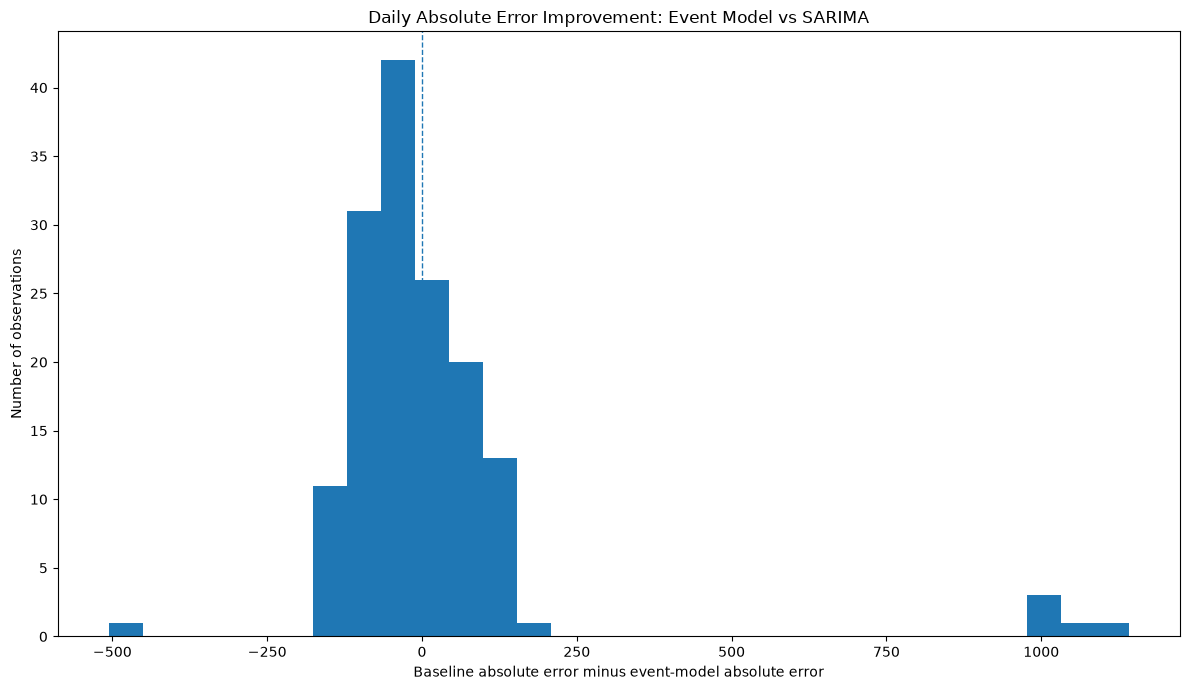

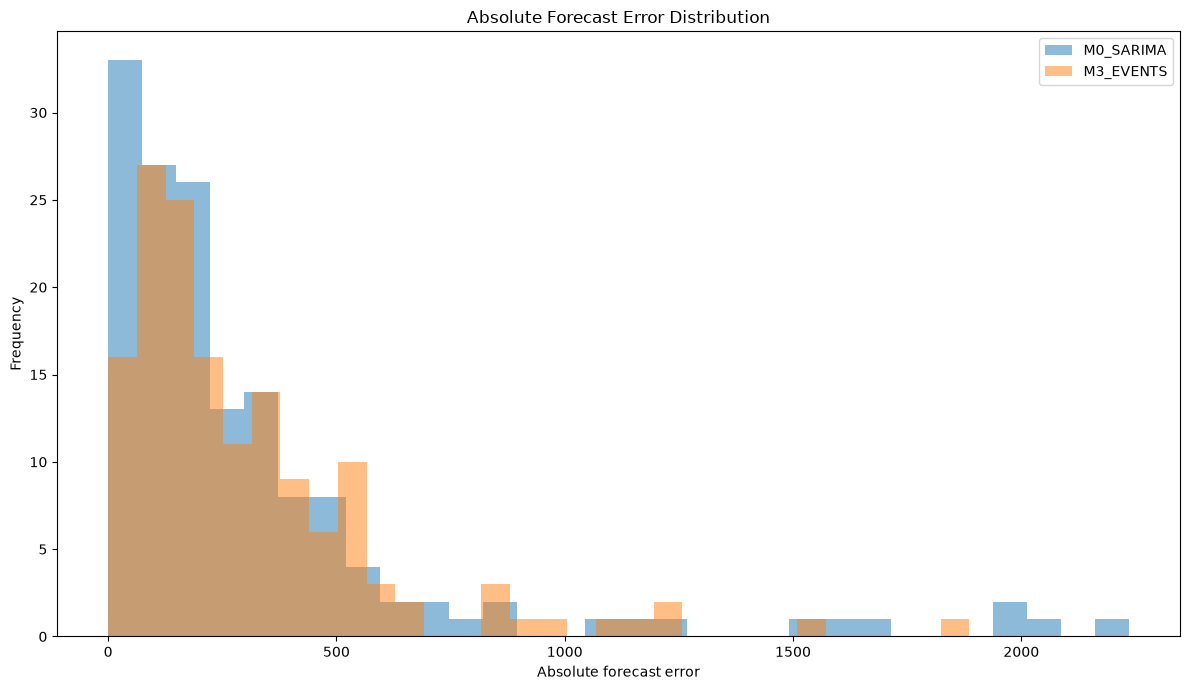

OVERALL ERROR SUMMARY


,model,mean_absolute_error,median_absolute_error,mean_error,error_std
0,M0_SARIMA,318.6076,190.9821,56.2226,519.7942
1,M3_EVENTS,303.6762,212.7922,74.7396,419.7970



FOLD ERROR ANALYSIS


,fold,baseline_mae,event_mae,mean_daily_improvement,median_daily_improvement,days_event_model_better,days_event_model_worse,days_tied
0,1,369.9619,310.9081,59.0538,41.0590,16,14,0
1,2,314.3235,297.9205,16.4030,-64.6743,13,17,0
2,3,367.2415,357.9630,9.2785,-33.4408,7,23,0
3,4,289.8460,275.5593,14.2868,1.6510,17,13,0
4,5,251.6648,276.0300,-24.3651,-32.5364,5,25,0



PAIRED DAILY ERRORS


model,fold,date,actual,M0_SARIMA,M3_EVENTS,baseline_absolute_error,event_absolute_error,event_improvement
0,1,2017-02-17,2946.0,2939.699457,3021.032000,6.300543,75.032000,-68.731457
1,1,2017-02-18,3462.0,2781.188773,2821.626751,680.811227,640.373249,40.437978
2,1,2017-02-19,1079.0,1323.027449,1462.467942,244.027449,383.467942,-139.440493
3,1,2017-02-20,2697.0,2814.306538,2927.812739,117.306538,230.812739,-113.506201
4,1,2017-02-21,2831.0,2908.491670,3015.406440,77.491670,184.406440,-106.914770
5,1,2017-02-22,3362.0,3188.951477,3282.745286,173.048523,79.254714,93.793809
6,1,2017-02-23,2983.0,2675.722397,2766.476388,307.277603,216.523612,90.753991
7,1,2017-02-24,3120.0,2957.400484,3085.403862,162.599516,34.596138,128.003378
8,1,2017-02-25,2741.0,2791.841457,2856.640879,50.841457,115.640879,-64.799421
9,1,2017-02-26,927.0,1330.372903,1482.899825,403.372903,555.899825,-152.526923



Error analysis completed.


In [53]:

# ============================================================
# CELL 43: FORECAST ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIGURE_DIR = Path("reports/stage_3/figures")
TABLE_DIR = Path("reports/stage_3/tables")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

BASELINE = "M0_SARIMA"
EVENT_MODEL = "M3_EVENTS"

# ------------------------------------------------------------
# 1. Prepare OOF data
# ------------------------------------------------------------

error_data = forecast_df[
    forecast_df["model"].isin(
        [BASELINE, EVENT_MODEL]
    )
].copy()

error_data["date"] = pd.to_datetime(
    error_data["date"]
)

error_data["forecast_error"] = (
    error_data["forecast"] - error_data["actual"]
)

error_data["absolute_error"] = (
    error_data["forecast_error"].abs()
)

# ------------------------------------------------------------
# 2. Pivot paired errors
# ------------------------------------------------------------

error_pivot = error_data.pivot(
    index=["fold", "date", "actual"],
    columns="model",
    values="forecast"
).reset_index()

error_pivot["baseline_error"] = (
    error_pivot[BASELINE] - error_pivot["actual"]
)

error_pivot["event_error"] = (
    error_pivot[EVENT_MODEL] - error_pivot["actual"]
)

error_pivot["baseline_absolute_error"] = (
    error_pivot["baseline_error"].abs()
)

error_pivot["event_absolute_error"] = (
    error_pivot["event_error"].abs()
)

error_pivot["absolute_error_difference"] = (
    error_pivot["event_absolute_error"]
    - error_pivot["baseline_absolute_error"]
)

error_pivot["event_improvement"] = (
    error_pivot["baseline_absolute_error"]
    - error_pivot["event_absolute_error"]
)

# Positive improvement = event model has smaller absolute error

# ------------------------------------------------------------
# 3. Overall paired error statistics
# ------------------------------------------------------------

error_summary = pd.DataFrame(
    {
        "model": [BASELINE, EVENT_MODEL],
        "mean_absolute_error": [
            error_pivot["baseline_absolute_error"].mean(),
            error_pivot["event_absolute_error"].mean(),
        ],
        "median_absolute_error": [
            error_pivot["baseline_absolute_error"].median(),
            error_pivot["event_absolute_error"].median(),
        ],
        "mean_error": [
            error_pivot["baseline_error"].mean(),
            error_pivot["event_error"].mean(),
        ],
        "error_std": [
            error_pivot["baseline_error"].std(),
            error_pivot["event_error"].std(),
        ],
    }
)

# ------------------------------------------------------------
# 4. Daily error improvement distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

ax.hist(
    error_pivot["event_improvement"],
    bins=30
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Daily Absolute Error Improvement: Event Model vs SARIMA"
)

ax.set_xlabel(
    "Baseline absolute error minus event-model absolute error"
)
ax.set_ylabel("Number of observations")

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "stage3_daily_error_improvement_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Error distributions
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

ax.hist(
    error_pivot["baseline_absolute_error"],
    bins=30,
    alpha=0.5,
    label=BASELINE
)

ax.hist(
    error_pivot["event_absolute_error"],
    bins=30,
    alpha=0.5,
    label=EVENT_MODEL
)

ax.set_title(
    "Absolute Forecast Error Distribution"
)

ax.set_xlabel("Absolute forecast error")
ax.set_ylabel("Frequency")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "stage3_absolute_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Fold-level paired error analysis
# ------------------------------------------------------------

fold_error_analysis = (
    error_pivot
    .groupby("fold", as_index=False)
    .agg(
        baseline_mae=("baseline_absolute_error", "mean"),
        event_mae=("event_absolute_error", "mean"),
        mean_daily_improvement=("event_improvement", "mean"),
        median_daily_improvement=("event_improvement", "median"),
        days_event_model_better=(
            "event_improvement",
            lambda x: (x > 0).sum()
        ),
        days_event_model_worse=(
            "event_improvement",
            lambda x: (x < 0).sum()
        ),
        days_tied=(
            "event_improvement",
            lambda x: np.isclose(x, 0).sum()
        ),
    )
)

# ------------------------------------------------------------
# 7. Save datasets
# ------------------------------------------------------------

error_pivot.to_csv(
    TABLE_DIR / "stage3_paired_daily_errors.csv",
    index=False
)

error_summary.to_csv(
    TABLE_DIR / "stage3_error_summary.csv",
    index=False
)

fold_error_analysis.to_csv(
    TABLE_DIR / "stage3_fold_error_analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------

print("OVERALL ERROR SUMMARY")
display(error_summary.round(4))

print("\nFOLD ERROR ANALYSIS")
display(fold_error_analysis.round(4))

print("\nPAIRED DAILY ERRORS")
display(
    error_pivot[
        [
            "fold",
            "date",
            "actual",
            BASELINE,
            EVENT_MODEL,
            "baseline_absolute_error",
            "event_absolute_error",
            "event_improvement",
        ]
    ].head(20)
)

print("\nError analysis completed.")


In [62]:
print("model_summary columns:")
print(model_summary.columns.tolist())

print("\nmodel_summary:")
display(model_summary.head())

print("\nsuccessful_results columns:")
print(successful_results.columns.tolist())

model_summary columns:
['model', 'successful_folds', 'mean_mae', 'median_mae', 'std_mae', 'mean_rmse', 'median_rmse', 'std_rmse', 'mean_bias', 'mae_rank', 'mae_improvement_pct', 'rmse_improvement_pct']

model_summary:


,model,successful_folds,mean_mae,median_mae,std_mae,mean_rmse,median_rmse,std_rmse,mean_bias,mae_rank,mae_improvement_pct,rmse_improvement_pct
0,M3_EVENTS,5,303.676164,297.920522,33.865009,423.588790,420.941801,38.942800,74.739567,1,4.686451,17.509747
1,M0_SARIMA,5,318.607551,314.323487,50.816910,513.501623,532.051983,99.132956,56.222600,2,0.000000,0.000000
2,M1_WEEKDAY,5,318.616390,314.326755,50.807501,513.506923,532.055303,99.130771,56.222167,3,-0.002774,-0.001032
3,M4_CALENDAR_EVENTS,5,355.525516,312.635598,119.919243,479.730683,475.968301,120.562044,119.066710,4,-11.587285,6.576599
4,M5_PROMOTIONS_RETROSPECTIVE,5,368.308234,390.195061,89.193235,531.162948,553.297371,123.025026,-24.354703,5,-15.599343,-3.439390



successful_results columns:
['model', 'fold', 'train_end', 'validation_start', 'validation_end', 'training_observations', 'validation_observations', 'feature_count', 'mae', 'rmse', 'bias_forecast_minus_actual', 'converged', 'fit_warning_count', 'prediction_warning_count', 'runtime_seconds', 'status']


In [63]:
# ============================================================
# CELL 43: STAGE 3 REPORT GENERATION
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. DIRECTORIES
# ------------------------------------------------------------

REPORT_DIR = Path("reports/stage_3")
TABLE_DIR = REPORT_DIR / "tables"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. PREPARE RANKING
# ------------------------------------------------------------

ranking = (
    model_summary
    .sort_values("mean_mae")
    .reset_index(drop=True)
    .copy()
)

# ------------------------------------------------------------
# 3. EXTRACT BASELINE AND EVENT MODEL
# ------------------------------------------------------------

baseline_row = ranking.loc[
    ranking["model"] == "M0_SARIMA"
].iloc[0]

event_row = ranking.loc[
    ranking["model"] == "M3_EVENTS"
].iloc[0]

event_robustness = robustness_summary.loc[
    robustness_summary["model"] == "M3_EVENTS"
].iloc[0]

# ------------------------------------------------------------
# 4. RANKING TABLE
# ------------------------------------------------------------

ranking_table = ranking[
    [
        "model",
        "successful_folds",
        "mean_mae",
        "median_mae",
        "std_mae",
        "mean_rmse",
        "mean_bias",
        "mae_improvement_pct",
        "rmse_improvement_pct"
    ]
].copy()

ranking_table.insert(
    0,
    "rank",
    range(1, len(ranking_table) + 1)
)

ranking_table = ranking_table.round(4)

ranking_markdown = ranking_table.to_markdown(
    index=False
)

# ------------------------------------------------------------
# 5. EVENT FOLD RESULTS
# ------------------------------------------------------------

event_fold_results = paired_comparison.loc[
    paired_comparison["model"] == "M3_EVENTS"
].copy()

event_fold_results = event_fold_results[
    [
        "fold",
        "mae",
        "rmse",
        "mae_improvement_pct",
        "rmse_improvement_pct"
    ]
].sort_values("fold")

event_fold_results = event_fold_results.round(4)

event_fold_markdown = event_fold_results.to_markdown(
    index=False
)

# ------------------------------------------------------------
# 6. ROBUSTNESS SUMMARY
# ------------------------------------------------------------

robustness_table = (
    robustness_summary
    .sort_values(
        "mean_mae_improvement_pct",
        ascending=False
    )
    .copy()
)

robustness_table = robustness_table.round(4)

robustness_markdown = robustness_table.to_markdown(
    index=False
)

# ------------------------------------------------------------
# 7. CALCULATE IMPROVEMENTS
# ------------------------------------------------------------

mae_improvement = (
    (baseline_row["mean_mae"] - event_row["mean_mae"])
    / baseline_row["mean_mae"]
) * 100

rmse_improvement = (
    (baseline_row["mean_rmse"] - event_row["mean_rmse"])
    / baseline_row["mean_rmse"]
) * 100

# ------------------------------------------------------------
# 8. BUILD REPORT
# ------------------------------------------------------------

report = f"""
# Stage 3: Exogenous Feature Analysis

## 1. Objective

Stage 3 investigated whether additional calendar, event and
promotion information could improve the forecasting
performance of the Stage 2 SARIMA champion.

The selected SARIMA specification was held fixed:

SARIMA(1,1,1)(0,1,1,7)

The objective was to evaluate incremental feature value
without unnecessarily expanding the model search.

---

## 2. Experimental Design

Seven forecasting configurations were evaluated across five
expanding-window validation folds.

Each fold used a 30-day forecast horizon.

Configurations evaluated:

- M0_SARIMA: Baseline SARIMA
- M1_WEEKDAY: Weekday features
- M2_CALENDAR: Calendar features
- M3_EVENTS: Applicable event features
- M4_CALENDAR_EVENTS: Calendar and event features
- M5_PROMOTIONS_RETROSPECTIVE: Retrospective promotion features
- M6_COMBINED_RETROSPECTIVE: Combined retrospective features

Metrics included MAE, RMSE, forecast bias, fold performance,
convergence and fit diagnostics.

---

## 3. Model Ranking

Models were ranked by mean MAE.

{ranking_markdown}

---

## 4. Leading Candidate: M3_EVENTS

The event-feature model achieved:

- Mean MAE: {event_row['mean_mae']:.4f}
- Median MAE: {event_row['median_mae']:.4f}
- Mean RMSE: {event_row['mean_rmse']:.4f}
- Mean forecast bias: {event_row['mean_bias']:.4f}
- Successful folds: {int(event_row['successful_folds'])}

Compared with the baseline:

- MAE improvement: {mae_improvement:.2f}%
- RMSE improvement: {rmse_improvement:.2f}%

The event-feature model produced the lowest mean MAE
among the evaluated configurations.

---

## 5. Fold-Level Robustness

The event model's fold-level performance is shown below.

{event_fold_markdown}

The event model recorded
{int(event_robustness['mae_wins'])} MAE wins,
{int(event_robustness['mae_ties'])} ties and
{int(event_robustness['mae_losses'])} losses against
the baseline across five validation folds.

Mean fold-level MAE improvement:
{event_robustness['mean_mae_improvement_pct']:.2f}%.

Median fold-level MAE improvement:
{event_robustness['median_mae_improvement_pct']:.2f}%.

Worst fold-level MAE improvement:
{event_robustness['min_mae_improvement_pct']:.2f}%.

Best fold-level MAE improvement:
{event_robustness['max_mae_improvement_pct']:.2f}%.

---

## 6. Robustness Comparison Across Models

{robustness_markdown}

---

## 7. Interpretation

### Event features

The M3_EVENTS configuration demonstrated the strongest
average forecasting performance among the evaluated
configurations.

It improved MAE in four of five validation folds.
However, it deteriorated in the fifth fold.

The results justify retaining the event configuration
as the leading experimental candidate, rather than
claiming universal superiority.

### Weekday features

Weekday features produced practically identical results
to the baseline.

The selected weekday specification therefore provided
little incremental forecasting value in this experiment.

### Calendar features

The calendar-only configuration was unstable across
validation folds.

Particularly severe deterioration occurred in folds
two, three and four.

Adding calendar variables did not automatically
improve forecasting performance.

### Promotions

The promotion experiment was retrospective because
observed promotion information was used in the
experimental setup.

Its results should not be interpreted as evidence of
operational forecasting performance unless future
promotional information is available and reliable
at forecast creation time.

### Combined features

Combined calendar and event configurations showed
mixed results.

Increasing the number of features did not guarantee
improved forecasting accuracy.

---

## 8. Limitations

- Only one store-product series was evaluated.
- Five validation folds were used.
- Each validation horizon contained 30 observations.
- Results may not generalize to other stores or products.
- Promotion experiments were retrospective.
- Event associations do not establish causality.
- Forecast accuracy improvements do not automatically
  translate into inventory or financial improvements.
- Feature availability at prediction time remains
  an operational requirement.

---

## 9. Stage 3 Decision

M3_EVENTS is retained as the leading experimental
forecasting configuration.

M0_SARIMA remains the baseline reference.

The observed improvement is promising, but further
validation is necessary before generalization.

Stage 3 is considered complete. Future forecasting
experimentation will be driven by inventory decision
requirements rather than indefinite model tuning.

---

## 10. Stage 4 Scope

Stage 4 will translate demand forecasting into
inventory decisions through:

1. Forecast uncertainty estimation.
2. Lead-time demand estimation.
3. Inventory position calculations.
4. Safety-stock estimation.
5. Reorder-point policies.
6. Service-level analysis.
7. Constrained replenishment optimization.
8. Inventory simulation and backtesting.

---

## 11. Figures

![Model MAE ranking](figures/stage3_model_mae_ranking.png)

![Fold-level MAE](figures/stage3_fold_mae.png)

![Paired fold improvements](figures/stage3_paired_mae_improvement.png)

![Actual vs forecast](figures/stage3_actual_vs_forecasts.png)

---

## Conclusion

Stage 3 demonstrated that additional features should
be evaluated empirically rather than assumed to improve
forecasting performance.

Applicable event features produced the strongest
average performance in this experiment, while
calendar and retrospective promotion configurations
showed mixed results.

The next stage focuses on transforming forecasts
into measurable inventory and replenishment decisions.
"""

# ------------------------------------------------------------
# 9. SAVE REPORT
# ------------------------------------------------------------

report_path = (
    REPORT_DIR / "stage3_exogenous_feature_analysis.md"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print("=" * 70)
print("STAGE 3 REPORT GENERATED SUCCESSFULLY")
print("=" * 70)

print("Report:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")

print("\nMAE improvement:", round(mae_improvement, 2), "%")
print("RMSE improvement:", round(rmse_improvement, 2), "%")

print("\nEvent model robustness:")
print(
    f"Wins: {int(event_robustness['mae_wins'])} | "
    f"Ties: {int(event_robustness['mae_ties'])} | "
    f"Losses: {int(event_robustness['mae_losses'])}"
)

STAGE 3 REPORT GENERATED SUCCESSFULLY
Report: reports/stage_3/stage3_exogenous_feature_analysis.md
Report size: 9398 bytes

MAE improvement: 4.69 %
RMSE improvement: 17.51 %

Event model robustness:
Wins: 4 | Ties: 0 | Losses: 1


In [64]:
# ============================================================
# CELL 44: STAGE 3 ARTIFACT INTEGRITY AUDIT
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. DIRECTORIES
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

REPORT_DIR = BASE_DIR / "reports/stage_3"
TABLE_DIR = REPORT_DIR / "tables"
FIGURE_DIR = REPORT_DIR / "figures"

# ------------------------------------------------------------
# 2. EXPECTED ARTIFACTS
# ------------------------------------------------------------

expected_files = [
    # Tables
    TABLE_DIR / "stage3_model_ranking.csv",
    TABLE_DIR / "stage3_fold_metrics.csv",
    TABLE_DIR / "stage3_oof_forecasts.csv",
    TABLE_DIR / "stage3_fit_diagnostics.csv",
    TABLE_DIR / "stage3_failed_fits.csv",
    TABLE_DIR / "stage3_model_ranking_with_improvement.csv",
    TABLE_DIR / "stage3_paired_fold_comparison.csv",
    TABLE_DIR / "stage3_robustness_summary.csv",
    TABLE_DIR / "stage3_figure_inventory.csv",

    # Figures
    FIGURE_DIR / "stage3_model_mae_ranking.png",
    FIGURE_DIR / "stage3_fold_mae.png",
    FIGURE_DIR / "stage3_paired_mae_improvement.png",
    FIGURE_DIR / "stage3_actual_vs_forecasts.png",

    # Report
    REPORT_DIR / "stage3_exogenous_feature_analysis.md",
]

# ------------------------------------------------------------
# 3. CHECK FILE EXISTENCE AND SIZE
# ------------------------------------------------------------

audit_records = []

for path in expected_files:

    exists = path.exists()

    size_bytes = (
        path.stat().st_size
        if exists and path.is_file()
        else 0
    )

    audit_records.append({
        "artifact": str(path.relative_to(BASE_DIR)),
        "exists": exists,
        "size_bytes": size_bytes,
        "status": "PASS" if exists and size_bytes > 0 else "FAIL"
    })

artifact_audit = pd.DataFrame(audit_records)

# ------------------------------------------------------------
# 4. MODEL FIT AUDIT
# ------------------------------------------------------------

fit_count = len(successful_results)

model_count = successful_results["model"].nunique()

fold_count = successful_results["fold"].nunique()

failed_fit_count = len(failed_results)

fit_audit = pd.DataFrame([{
    "successful_fit_records": fit_count,
    "distinct_models": model_count,
    "distinct_folds": fold_count,
    "failed_fit_records": failed_fit_count,
    "expected_successful_fits": 35,
    "fit_count_check": fit_count == 35,
    "failure_check": failed_fit_count == 0
}])

# ------------------------------------------------------------
# 5. SAVE ARTIFACT AUDIT
# ------------------------------------------------------------

audit_path = TABLE_DIR / "stage3_artifact_audit.csv"

artifact_audit.to_csv(
    audit_path,
    index=False
)

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("STAGE 3 ARTIFACT AUDIT")
print("=" * 70)

display(artifact_audit)

print("\nFIT AUDIT")
display(fit_audit)

missing_artifacts = artifact_audit.loc[
    artifact_audit["status"] == "FAIL"
]

print("\nMissing or empty artifacts:", len(missing_artifacts))

if len(missing_artifacts) > 0:

    display(missing_artifacts)

else:

    print("All expected artifacts exist and are non-empty.")

# ------------------------------------------------------------
# 7. FINAL STATUS
# ------------------------------------------------------------

artifact_pass = len(missing_artifacts) == 0

fit_pass = (
    fit_count == 35
    and failed_fit_count == 0
)

if artifact_pass and fit_pass:

    print("\n" + "=" * 70)
    print("STAGE 3 INTEGRITY AUDIT PASSED")
    print("=" * 70)

else:

    print("\n" + "=" * 70)
    print("STAGE 3 INTEGRITY AUDIT REQUIRES ATTENTION")
    print("=" * 70)

STAGE 3 ARTIFACT AUDIT


,artifact,exists,size_bytes,status
0,reports/stage_3/tables/stage3_model_ranking.csv,False,0,FAIL
1,reports/stage_3/tables/stage3_fold_metrics.csv,False,0,FAIL
2,reports/stage_3/tables/stage3_oof_forecasts.csv,False,0,FAIL
3,reports/stage_3/tables/stage3_fit_diagnostics.csv,False,0,FAIL
4,reports/stage_3/tables/stage3_failed_fits.csv,False,0,FAIL
5,reports/stage_3/tables/stage3_model_ranking_wi...,True,1422,PASS
6,reports/stage_3/tables/stage3_paired_fold_comp...,True,9957,PASS
7,reports/stage_3/tables/stage3_robustness_summa...,True,946,PASS
8,reports/stage_3/tables/stage3_figure_inventory...,False,0,FAIL
9,reports/stage_3/figures/stage3_model_mae_ranki...,True,127785,PASS



FIT AUDIT


,successful_fit_records,distinct_models,distinct_folds,failed_fit_records,expected_successful_fits,fit_count_check,failure_check
0,35,7,5,0,35,True,True



Missing or empty artifacts: 8


,artifact,exists,size_bytes,status
0,reports/stage_3/tables/stage3_model_ranking.csv,False,0,FAIL
1,reports/stage_3/tables/stage3_fold_metrics.csv,False,0,FAIL
2,reports/stage_3/tables/stage3_oof_forecasts.csv,False,0,FAIL
3,reports/stage_3/tables/stage3_fit_diagnostics.csv,False,0,FAIL
4,reports/stage_3/tables/stage3_failed_fits.csv,False,0,FAIL
8,reports/stage_3/tables/stage3_figure_inventory...,False,0,FAIL
11,reports/stage_3/figures/stage3_paired_mae_impr...,False,0,FAIL
12,reports/stage_3/figures/stage3_actual_vs_forec...,False,0,FAIL



STAGE 3 INTEGRITY AUDIT REQUIRES ATTENTION


In [65]:
# ============================================================
# STAGE 4 - MILESTONE 12
# BLOCK 1: OOF FORECAST DATA AUDIT
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. INSPECT OOF FORECAST DATA
# ------------------------------------------------------------

print("forecast_df shape:", forecast_df.shape)

print("\nColumns:")
print(forecast_df.columns.tolist())

print("\nSample:")
display(forecast_df.head())

# ------------------------------------------------------------
# 2. INSPECT EVENT MODEL FORECASTS
# ------------------------------------------------------------

event_forecasts = forecast_df.loc[
    forecast_df["model"] == "M3_EVENTS"
].copy()

print("\nEvent model OOF shape:")
print(event_forecasts.shape)

display(event_forecasts.head())

# ------------------------------------------------------------
# 3. CHECK DATA QUALITY
# ------------------------------------------------------------

print("\nMissing values:")
display(event_forecasts.isna().sum())

print("\nUnique folds:")
print(event_forecasts["fold"].unique())

print("\nDates:")
print(event_forecasts["date"].min())
print(event_forecasts["date"].max())

# ------------------------------------------------------------
# 4. BASIC FORECAST ERROR
# ------------------------------------------------------------

event_forecasts["error"] = (
    event_forecasts["forecast"]
    - event_forecasts["actual"]
)

event_forecasts["absolute_error"] = (
    event_forecasts["error"].abs()
)

event_forecasts["squared_error"] = (
    event_forecasts["error"] ** 2
)

print("\nError statistics:")
display(
    event_forecasts[
        ["error", "absolute_error", "squared_error"]
    ].describe()
)

# ------------------------------------------------------------
# 5. FOLD-LEVEL ERROR AUDIT
# ------------------------------------------------------------

fold_error_summary = (
    event_forecasts
    .groupby("fold")
    .agg(
        observations=("error", "count"),
        mean_error=("error", "mean"),
        mae=("absolute_error", "mean"),
        rmse=("squared_error", lambda x: np.sqrt(x.mean())),
        median_error=("error", "median"),
        error_std=("error", "std")
    )
    .reset_index()
)

print("\nFold error summary:")
display(fold_error_summary)

forecast_df shape: (1050, 6)

Columns:
['model', 'fold', 'date', 'actual', 'forecast', 'error_forecast_minus_actual']

Sample:


,model,fold,date,actual,forecast,error_forecast_minus_actual
0,M0_SARIMA,1,2017-02-17,2946.0,2939.699457,-6.300543
1,M0_SARIMA,1,2017-02-18,3462.0,2781.188773,-680.811227
2,M0_SARIMA,1,2017-02-19,1079.0,1323.027449,244.027449
3,M0_SARIMA,1,2017-02-20,2697.0,2814.306538,117.306538
4,M0_SARIMA,1,2017-02-21,2831.0,2908.491670,77.491670



Event model OOF shape:
(150, 6)


,model,fold,date,actual,forecast,error_forecast_minus_actual
450,M3_EVENTS,1,2017-02-17,2946.0,3021.032000,75.032000
451,M3_EVENTS,1,2017-02-18,3462.0,2821.626751,-640.373249
452,M3_EVENTS,1,2017-02-19,1079.0,1462.467942,383.467942
453,M3_EVENTS,1,2017-02-20,2697.0,2927.812739,230.812739
454,M3_EVENTS,1,2017-02-21,2831.0,3015.406440,184.406440



Missing values:


model                          0
fold                           0
date                           0
actual                         0
forecast                       0
error_forecast_minus_actual    0
dtype: int64


Unique folds:
[1 2 3 4 5]

Dates:
2017-02-17 00:00:00
2017-07-16 00:00:00

Error statistics:


,error,absolute_error,squared_error
count,150.000000,150.000000,1.500000e+02
mean,74.739567,303.676164,1.806407e+05
std,419.797043,298.353677,4.240386e+05
min,-1885.935682,0.148336,2.200361e-02
25%,-79.479165,110.431078,1.219869e+04
50%,115.921133,212.792219,4.529147e+04
75%,294.875020,385.729152,1.487873e+05
max,1245.370685,1885.935682,3.556753e+06



Fold error summary:


,fold,observations,mean_error,mae,rmse,median_error,error_std
0,1,30,-20.798720,310.908089,481.156023,76.817406,488.924081
1,2,30,98.838596,297.920522,420.941801,108.876245,416.168399
2,3,30,218.350282,357.962957,439.184687,281.888889,387.573811
3,4,30,-38.922551,275.559259,385.530825,-11.755673,390.118088
4,5,30,116.230226,276.029992,391.130615,177.148862,379.846193
